# Sentinel-2 Coastline Benchmarking: Offsets Evaluation

This notebook evaluates the performance of different coastline extraction models (both index-based and deep learning-based) by analyzing the **offsets**. An offset is defined as the cross-shore distance between the predicted coastline and the ground truth (reference) coastline.

The analysis is divided into several sections:
1. **Data Loading and Preprocessing**: Reading the offshore transects data for both study areas (Puntal and Salinas).
2. **Metrics Calculation**: Computing robust metrics (such as MAD, IQR, MAE, Bias, RMSE, etc.) to evaluate coastline extraction accuracy.
3. **Research Questions (Q-based Analysis)**: Visualizing and answering specific study questions through detailed plots mapping errors by distance, model comparison, brightness correlation, etc.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# Add project root to sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

In [2]:
# Target Study Areas and General setup
STUDY_NAMES = ["puntal", "salinas"]
# Base directories
OFFSETS_DIR = Path("..") / "results" / "offsets"

# Load offsets CSV for each study area and type of models (index-based and DL segmentation)
off_puntal_index = pd.read_csv(OFFSETS_DIR / "puntal_sdw_indexes_offset.csv")
off_puntal_dl = pd.read_csv(OFFSETS_DIR / "puntal_sdw_dl_offset.csv")

off_salinas_index = pd.read_csv(OFFSETS_DIR / "salinas_sdw_indexes_offset.csv")
off_salinas_dl = pd.read_csv(OFFSETS_DIR / "salinas_sdw_dl_offset.csv")

# Add a column to identify the study area and model type for easier plotting later
off_puntal_index['Study Area'] = 'Puntal'
off_puntal_index['Model Type'] = 'Index-based'
off_puntal_dl['Study Area'] = 'Puntal'
off_puntal_dl['Model Type'] = 'DL-based'
off_salinas_index['Study Area'] = 'Salinas'
off_salinas_index['Model Type'] = 'Index-based'
off_salinas_dl['Study Area'] = 'Salinas'
off_salinas_dl['Model Type'] = 'DL-based'

# Print heads of the loaded DataFrames to verify
print("Puntal Index-based Offsets:")
display(off_puntal_index.head())
print("\nPuntal DL-based Offsets:")
display(off_puntal_dl.head())
print("\nSalinas Index-based Offsets:")
display(off_salinas_index.head())
print("\nSalinas DL-based Offsets:")
display(off_salinas_dl.head())

/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_4434/1659104328.py:7: DtypeWarning: Columns (0: towards_sea) have mixed types. Specify dtype option on import or set low_memory=False.
  off_puntal_index = pd.read_csv(OFFSETS_DIR / "puntal_sdw_indexes_offset.csv")


Puntal Index-based Offsets:


,transect_id,shore_id,distance_from_base,date,index,thres_type,thres_val,up_factor,geometry,date_h,...,tide,tide_is_rising,tide_is_rising_and_low_tide,offset,towards_sea,is_outlier,offset_sign,distance_from_base_wl,Study Area,Model Type
0,1,614,307.820459,2015-08-01 11:10:36,AWEINSH,(0),0.000000,2,POINT (437557.75540000014 4812107.2017),2015-08-01 11:00:00,...,1.206,True,True,27.269935,True,False,27.269935,280.550524,Puntal,Index-based
1,1,666,302.355156,2015-08-01 11:10:36,AWEINSH,(Otsu Modified),-676.063800,2,POINT (437556.1001000004 4812101.993100001),2015-08-01 11:00:00,...,1.206,True,True,21.804632,True,False,21.804632,280.550524,Puntal,Index-based
2,1,866,291.042099,2015-08-01 11:10:36,AWEINSH,(Otsu),-3412.249500,2,POINT (437552.67370000016 4812091.2114),2015-08-01 11:00:00,...,1.206,True,True,10.491575,True,False,10.491575,280.550524,Puntal,Index-based
3,1,1124,279.704720,2015-08-01 11:10:36,MNDWI,(0),0.000000,2,POINT (437549.2400000002 4812080.4065000005),2015-08-01 11:00:00,...,1.206,True,True,0.845804,False,False,-0.845804,280.550524,Puntal,Index-based
4,1,119,294.601909,2015-08-01 11:10:36,MNDWI,(Otsu Modified),0.169576,2,POINT (437553.75189999957 4812094.604),2015-08-01 11:00:00,...,1.206,True,True,14.051385,True,False,14.051385,280.550524,Puntal,Index-based



Puntal DL-based Offsets:


,transect_id,shore_id,distance_from_base,date,arch,encoder,model_name,geometry,date_h,sinuosity,...,tide,tide_is_rising,tide_is_rising_and_low_tide,offset,towards_sea,is_outlier,offset_sign,distance_from_base_wl,Study Area,Model Type
0,1,1,265.097857,2015-12-09,deeplabv3plus,efficientnet-b4,deeplabv3plus_efficientnet-b4,POINT (437544.81599999964 4812066.4857),2015-12-09 11:00:00,1.596648,...,2.774,True,True,2.298856,True,False,2.298856,262.799001,Puntal,DL-based
1,1,2,261.349397,2015-12-09,deeplabv3plus,efficientnet-b7,deeplabv3plus_efficientnet-b7,POINT (437543.6807000004 4812062.9133),2015-12-09 11:00:00,1.590617,...,2.774,True,True,1.449604,False,False,-1.449604,262.799001,Puntal,DL-based
2,1,3,260.825197,2015-12-09,deeplabv3plus,mit_b2,deeplabv3plus_mit_b2,POINT (437543.5219999999 4812062.413699999),2015-12-09 11:00:00,1.586094,...,2.774,True,True,1.973804,False,False,-1.973804,262.799001,Puntal,DL-based
3,1,4,261.814234,2015-12-09,deeplabv3plus,mit_b4,deeplabv3plus_mit_b4,POINT (437543.8214999996 4812063.3563),2015-12-09 11:00:00,1.589886,...,2.774,True,True,0.984767,False,False,-0.984767,262.799001,Puntal,DL-based
4,1,5,257.658022,2015-12-09,segformer,efficientnet-b4,segformer_efficientnet-b4,POINT (437542.56269999966 4812059.395300001),2015-12-09 11:00:00,1.587405,...,2.774,True,True,5.140979,False,False,-5.140979,262.799001,Puntal,DL-based



Salinas Index-based Offsets:


,transect_id,shore_id,distance_from_base,date,index,thres_type,thres_val,up_factor,geometry,date_h,...,wave_dir,tide_is_rising,tide_is_rising_and_low_tide,offset,towards_sea,is_outlier,offset_sign,distance_from_base_wl,Study Area,Model Type
0,1,3,206.648226,2015-07-25 11:20:46,AWEINSH,(0),0.000000,2,POINT (260744.4129999997 4829222.892000001),2015-07-25 11:00:00,...,325.0,False,False,19.951105,True,False,19.951105,186.697121,Salinas,Index-based
1,1,2,195.520920,2015-07-25 11:20:46,AWEINSH,(Otsu Modified),-2447.280500,2,POINT (260745.8805999998 4829211.8619),2015-07-25 11:00:00,...,325.0,False,False,8.823799,True,False,8.823799,186.697121,Salinas,Index-based
2,1,1,188.896847,2015-07-25 11:20:46,AWEINSH,(Otsu),-3725.117700,2,POINT (260746.75430000015 4829205.295700001),2015-07-25 11:00:00,...,325.0,False,False,2.199726,True,False,2.199726,186.697121,Salinas,Index-based
3,1,6,184.152196,2015-07-25 11:20:46,MNDWI,(0),0.000000,2,POINT (260747.38009999972 4829200.592499999),2015-07-25 11:00:00,...,325.0,False,False,2.544925,False,False,-2.544925,186.697121,Salinas,Index-based
4,1,5,203.847360,2015-07-25 11:20:46,MNDWI,(Otsu Modified),0.232896,2,POINT (260744.7823999999 4829220.115599999),2015-07-25 11:00:00,...,325.0,False,False,17.150239,True,False,17.150239,186.697121,Salinas,Index-based



Salinas DL-based Offsets:


,transect_id,shore_id,distance_from_base,date,arch,encoder,model_name,geometry,date_h,sinuosity,...,wave_dir,tide_is_rising,tide_is_rising_and_low_tide,offset,towards_sea,is_outlier,offset_sign,distance_from_base_wl,Study Area,Model Type
0,1,1,197.413253,2015-07-25,deeplabv3plus,efficientnet-b4,deeplabv3plus_efficientnet-b4,POINT (260745.63100000005 4829213.7377),2015-07-25 11:00:00,7.791411,...,325.0,False,False,10.716132,True,False,10.716132,186.697121,Salinas,DL-based
1,1,2,196.257349,2015-07-25,deeplabv3plus,efficientnet-b7,deeplabv3plus_efficientnet-b7,POINT (260745.7834999999 4829212.5919),2015-07-25 11:00:00,10.324629,...,325.0,False,False,9.560228,True,False,9.560228,186.697121,Salinas,DL-based
2,1,3,185.815120,2015-07-25,deeplabv3plus,mit_b2,deeplabv3plus_mit_b2,POINT (260747.16079999972 4829202.240900001),2015-07-25 11:00:00,8.210679,...,325.0,False,False,0.882001,False,False,-0.882001,186.697121,Salinas,DL-based
3,1,4,196.866776,2015-07-25,deeplabv3plus,mit_b4,deeplabv3plus_mit_b4,POINT (260745.70309999958 4829213.196),2015-07-25 11:00:00,8.326054,...,325.0,False,False,10.169655,True,False,10.169655,186.697121,Salinas,DL-based
4,1,5,197.849968,2015-07-25,segformer,efficientnet-b4,segformer_efficientnet-b4,POINT (260745.5734000001 4829214.170600001),2015-07-25 11:00:00,10.492577,...,325.0,False,False,11.152847,True,False,11.152847,186.697121,Salinas,DL-based


In [3]:
# Correct values for certain fields
index_field = {
    "SCOWI": "SCoWI",
    "AWEINSH": "AWEInsh"
    }
threshold_field = {
    "(0)": "(Zero)",
    "(Otsu Modified)": "(LM Otsu)"
    }
arch_field = {
    "unet": "U-Net",
    "deeplabv3plus": "DeepLabV3+",
    "segformer": "SegFormer"
}
encoder_field = {
    "efficientnet-b4": "EfficientNet-B4",
    "efficientnet-b7": "EfficientNet-B7",
    "mit_b2": "MiT-B2",
    "mit_b4": "MiT-B4"
}

# Apply corrections to the DataFrames
off_puntal_index["index"] = off_puntal_index["index"].replace(index_field)
off_puntal_index["thres_type"] = off_puntal_index["thres_type"].replace(threshold_field)
off_puntal_dl["arch"] = off_puntal_dl["arch"].replace(arch_field)
off_puntal_dl["encoder"] = off_puntal_dl["encoder"].replace(encoder_field)
off_salinas_index["index"] = off_salinas_index["index"].replace(index_field)
off_salinas_index["thres_type"] = off_salinas_index["thres_type"].replace(threshold_field)
off_salinas_dl["arch"] = off_salinas_dl["arch"].replace(arch_field)
off_salinas_dl["encoder"] = off_salinas_dl["encoder"].replace(encoder_field)

# Create a combined column
off_puntal_index["model_name"] = off_puntal_index.apply(lambda row: f"{row['index']} {row['thres_type']}", axis=1)
off_salinas_index["model_name"] = off_salinas_index.apply(lambda row: f"{row['index']} {row['thres_type']}", axis=1)
off_puntal_dl["model_name"] = off_puntal_dl.apply(lambda row: f"{row['arch']} ({row['encoder']})", axis=1)
off_salinas_dl["model_name"] = off_salinas_dl.apply(lambda row: f"{row['arch']} ({row['encoder']})", axis=1)

# Display the updated DataFrames to verify changes
print("Updated Puntal Index-based Offsets:")
display(off_puntal_index.head())
print("\nUpdated Puntal DL-based Offsets:")
display(off_puntal_dl.head())
print("\nUpdated Salinas Index-based Offsets:")
display(off_salinas_index.head())
print("\nUpdated Salinas DL-based Offsets:")
display(off_salinas_dl.head())

Updated Puntal Index-based Offsets:


,transect_id,shore_id,distance_from_base,date,index,thres_type,thres_val,up_factor,geometry,date_h,...,tide_is_rising,tide_is_rising_and_low_tide,offset,towards_sea,is_outlier,offset_sign,distance_from_base_wl,Study Area,Model Type,model_name
0,1,614,307.820459,2015-08-01 11:10:36,AWEInsh,(Zero),0.000000,2,POINT (437557.75540000014 4812107.2017),2015-08-01 11:00:00,...,True,True,27.269935,True,False,27.269935,280.550524,Puntal,Index-based,AWEInsh (Zero)
1,1,666,302.355156,2015-08-01 11:10:36,AWEInsh,(LM Otsu),-676.063800,2,POINT (437556.1001000004 4812101.993100001),2015-08-01 11:00:00,...,True,True,21.804632,True,False,21.804632,280.550524,Puntal,Index-based,AWEInsh (LM Otsu)
2,1,866,291.042099,2015-08-01 11:10:36,AWEInsh,(Otsu),-3412.249500,2,POINT (437552.67370000016 4812091.2114),2015-08-01 11:00:00,...,True,True,10.491575,True,False,10.491575,280.550524,Puntal,Index-based,AWEInsh (Otsu)
3,1,1124,279.704720,2015-08-01 11:10:36,MNDWI,(Zero),0.000000,2,POINT (437549.2400000002 4812080.4065000005),2015-08-01 11:00:00,...,True,True,0.845804,False,False,-0.845804,280.550524,Puntal,Index-based,MNDWI (Zero)
4,1,119,294.601909,2015-08-01 11:10:36,MNDWI,(LM Otsu),0.169576,2,POINT (437553.75189999957 4812094.604),2015-08-01 11:00:00,...,True,True,14.051385,True,False,14.051385,280.550524,Puntal,Index-based,MNDWI (LM Otsu)



Updated Puntal DL-based Offsets:


,transect_id,shore_id,distance_from_base,date,arch,encoder,model_name,geometry,date_h,sinuosity,...,tide,tide_is_rising,tide_is_rising_and_low_tide,offset,towards_sea,is_outlier,offset_sign,distance_from_base_wl,Study Area,Model Type
0,1,1,265.097857,2015-12-09,DeepLabV3+,EfficientNet-B4,DeepLabV3+ (EfficientNet-B4),POINT (437544.81599999964 4812066.4857),2015-12-09 11:00:00,1.596648,...,2.774,True,True,2.298856,True,False,2.298856,262.799001,Puntal,DL-based
1,1,2,261.349397,2015-12-09,DeepLabV3+,EfficientNet-B7,DeepLabV3+ (EfficientNet-B7),POINT (437543.6807000004 4812062.9133),2015-12-09 11:00:00,1.590617,...,2.774,True,True,1.449604,False,False,-1.449604,262.799001,Puntal,DL-based
2,1,3,260.825197,2015-12-09,DeepLabV3+,MiT-B2,DeepLabV3+ (MiT-B2),POINT (437543.5219999999 4812062.413699999),2015-12-09 11:00:00,1.586094,...,2.774,True,True,1.973804,False,False,-1.973804,262.799001,Puntal,DL-based
3,1,4,261.814234,2015-12-09,DeepLabV3+,MiT-B4,DeepLabV3+ (MiT-B4),POINT (437543.8214999996 4812063.3563),2015-12-09 11:00:00,1.589886,...,2.774,True,True,0.984767,False,False,-0.984767,262.799001,Puntal,DL-based
4,1,5,257.658022,2015-12-09,SegFormer,EfficientNet-B4,SegFormer (EfficientNet-B4),POINT (437542.56269999966 4812059.395300001),2015-12-09 11:00:00,1.587405,...,2.774,True,True,5.140979,False,False,-5.140979,262.799001,Puntal,DL-based



Updated Salinas Index-based Offsets:


,transect_id,shore_id,distance_from_base,date,index,thres_type,thres_val,up_factor,geometry,date_h,...,tide_is_rising,tide_is_rising_and_low_tide,offset,towards_sea,is_outlier,offset_sign,distance_from_base_wl,Study Area,Model Type,model_name
0,1,3,206.648226,2015-07-25 11:20:46,AWEInsh,(Zero),0.000000,2,POINT (260744.4129999997 4829222.892000001),2015-07-25 11:00:00,...,False,False,19.951105,True,False,19.951105,186.697121,Salinas,Index-based,AWEInsh (Zero)
1,1,2,195.520920,2015-07-25 11:20:46,AWEInsh,(LM Otsu),-2447.280500,2,POINT (260745.8805999998 4829211.8619),2015-07-25 11:00:00,...,False,False,8.823799,True,False,8.823799,186.697121,Salinas,Index-based,AWEInsh (LM Otsu)
2,1,1,188.896847,2015-07-25 11:20:46,AWEInsh,(Otsu),-3725.117700,2,POINT (260746.75430000015 4829205.295700001),2015-07-25 11:00:00,...,False,False,2.199726,True,False,2.199726,186.697121,Salinas,Index-based,AWEInsh (Otsu)
3,1,6,184.152196,2015-07-25 11:20:46,MNDWI,(Zero),0.000000,2,POINT (260747.38009999972 4829200.592499999),2015-07-25 11:00:00,...,False,False,2.544925,False,False,-2.544925,186.697121,Salinas,Index-based,MNDWI (Zero)
4,1,5,203.847360,2015-07-25 11:20:46,MNDWI,(LM Otsu),0.232896,2,POINT (260744.7823999999 4829220.115599999),2015-07-25 11:00:00,...,False,False,17.150239,True,False,17.150239,186.697121,Salinas,Index-based,MNDWI (LM Otsu)



Updated Salinas DL-based Offsets:


,transect_id,shore_id,distance_from_base,date,arch,encoder,model_name,geometry,date_h,sinuosity,...,wave_dir,tide_is_rising,tide_is_rising_and_low_tide,offset,towards_sea,is_outlier,offset_sign,distance_from_base_wl,Study Area,Model Type
0,1,1,197.413253,2015-07-25,DeepLabV3+,EfficientNet-B4,DeepLabV3+ (EfficientNet-B4),POINT (260745.63100000005 4829213.7377),2015-07-25 11:00:00,7.791411,...,325.0,False,False,10.716132,True,False,10.716132,186.697121,Salinas,DL-based
1,1,2,196.257349,2015-07-25,DeepLabV3+,EfficientNet-B7,DeepLabV3+ (EfficientNet-B7),POINT (260745.7834999999 4829212.5919),2015-07-25 11:00:00,10.324629,...,325.0,False,False,9.560228,True,False,9.560228,186.697121,Salinas,DL-based
2,1,3,185.815120,2015-07-25,DeepLabV3+,MiT-B2,DeepLabV3+ (MiT-B2),POINT (260747.16079999972 4829202.240900001),2015-07-25 11:00:00,8.210679,...,325.0,False,False,0.882001,False,False,-0.882001,186.697121,Salinas,DL-based
3,1,4,196.866776,2015-07-25,DeepLabV3+,MiT-B4,DeepLabV3+ (MiT-B4),POINT (260745.70309999958 4829213.196),2015-07-25 11:00:00,8.326054,...,325.0,False,False,10.169655,True,False,10.169655,186.697121,Salinas,DL-based
4,1,5,197.849968,2015-07-25,SegFormer,EfficientNet-B4,SegFormer (EfficientNet-B4),POINT (260745.5734000001 4829214.170600001),2015-07-25 11:00:00,10.492577,...,325.0,False,False,11.152847,True,False,11.152847,186.697121,Salinas,DL-based


In [4]:
# Define a dictionary to set a color for each model type
model_colors = {
    # Index-based models
    "NDWI": "#4B4B91",
    "MNDWI": "#DEBF33",
    "SCoWI": "#E15759",
    "AWEInsh": "#76B7B2",
    # DL-based models
    "U-Net": "#59A14F",
    "DeepLabV3+": "#BD7B9B",
    "SegFormer": "#E79316"
}
thres_encoder_markers = {
    "(Zero)": "o",
    "(Otsu)": "s",
    "(LM Otsu)": "^",
    "EfficientNet-B4": "o",
    "EfficientNet-B7": "s",
    "MiT-B2": "^",
    "MiT-B4": "D"
}

## 2. Evaluation Metrics Calculation

In this section, we define the core metrics used to evaluate the cross-shore errors (offsets). These include:
- **MAD (Median Absolute Deviation)**: Robust estimate of the typical error magnitude.
- **IQR (Interquartile Range)**: Represents the spread or variance of the error robustly.
- **MAE (Mean Absolute Error)**: Conventional measure of the absolute average prediction error.
- **Bias (Mean error)**: Indicates the general tendency of the model to predict seaward or landward.
- **RMSE (Root Mean Square Error)**: Emphasizes larger errors.
- **R² (Determination Coefficient)**: Indicates the variance explained.

*Note: For the `Overall` metrics, a macro-average is computed giving equal (50%) weight to Puntal and Salinas datasets, mitigating representation biases due to differing amounts of data.*

In [5]:
from sklearn.metrics import median_absolute_error, mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

# Perform the calculation of interest metrics for each model and study area
metrics = ["MAD", "IQR", "MAE", "Bias", "RMSE", "R²"]

def calculate_metrics(off_df):
    study_metrics = []
    for model_name in off_df["model_name"].unique():
        model_data = off_df[off_df["model_name"] == model_name]
        # Drop nan values for metric calculations
        model_data = model_data.dropna(subset=["distance_from_base_wl", "distance_from_base"])

        true_values = model_data["distance_from_base_wl"].values
        pred_values = model_data["distance_from_base"].values
        
        mad = median_absolute_error(true_values, pred_values)
        iqr = np.percentile(pred_values - true_values, 75) - np.percentile(pred_values - true_values, 25)
        mae = mean_absolute_error(true_values, pred_values)
        bias = np.mean(pred_values - true_values)
        rmse = np.sqrt(mean_squared_error(true_values, pred_values))
        corr, _ = pearsonr(true_values, pred_values)
        r2 = corr ** 2
        
        study_metrics.append({
            "model_name": model_name,
            "MAD": mad,
            "IQR": iqr,
            "MAE": mae,
            "Bias": bias,
            "RMSE": rmse,
            "R²": r2
        })
    return pd.DataFrame(study_metrics)

# Index-based models
puntal_index_metrics = calculate_metrics(off_puntal_index)
salinas_index_metrics = calculate_metrics(off_salinas_index)
overall_index_metrics = calculate_metrics(pd.concat([off_puntal_index, off_salinas_index], ignore_index=True))

# DL-based models
puntal_dl_metrics = calculate_metrics(off_puntal_dl)
salinas_dl_metrics = calculate_metrics(off_salinas_dl)
overall_dl_metrics = calculate_metrics(pd.concat([off_puntal_dl, off_salinas_dl], ignore_index=True))

# Append metrics by Study Area as well
salinas_metrics = pd.concat([salinas_index_metrics, salinas_dl_metrics], ignore_index=True)
puntal_metrics = pd.concat([puntal_index_metrics, puntal_dl_metrics], ignore_index=True)

In [6]:
from sklearn.metrics import median_absolute_error, mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr
import numpy as np
import pandas as pd

# Perform the calculation of interest metrics for each model and study area
metrics_list = ["MAD", "IQR", "MAE", "Bias", "RMSE", "R²"]

def calculate_metrics(off_df):
    study_metrics = []
    for model_name in off_df["model_name"].unique():
        model_data = off_df[off_df["model_name"] == model_name]
        # Drop nan values for metric calculations
        model_data = model_data.dropna(subset=["distance_from_base_wl", "distance_from_base"])

        true_values = model_data["distance_from_base_wl"].values
        pred_values = model_data["distance_from_base"].values
        
        mad = median_absolute_error(true_values, pred_values)
        iqr = np.percentile(pred_values - true_values, 75) - np.percentile(pred_values - true_values, 25)
        mae = mean_absolute_error(true_values, pred_values)
        bias = np.mean(pred_values - true_values)
        rmse = np.sqrt(mean_squared_error(true_values, pred_values))
        corr, _ = pearsonr(true_values, pred_values)
        r2 = corr ** 2
        
        study_metrics.append({
            "model_name": model_name,
            "MAD": mad,
            "IQR": iqr,
            "MAE": mae,
            "Bias": bias,
            "RMSE": rmse,
            "R²": r2
        })
    return pd.DataFrame(study_metrics)

# Index-based models
puntal_index_metrics = calculate_metrics(off_puntal_index)
salinas_index_metrics = calculate_metrics(off_salinas_index)

# Calculamos el macro-average devolviendo exactamente un 50% de peso a cada área
overall_index_metrics = puntal_index_metrics.copy()
for metric in metrics_list:
    overall_index_metrics[metric] = (puntal_index_metrics[metric] + salinas_index_metrics[metric]) / 2.0

# DL-based models
puntal_dl_metrics = calculate_metrics(off_puntal_dl)
salinas_dl_metrics = calculate_metrics(off_salinas_dl)

# Macro-average para modelos de Deep Learning
overall_dl_metrics = puntal_dl_metrics.copy()
for metric in metrics_list:
    overall_dl_metrics[metric] = (puntal_dl_metrics[metric] + salinas_dl_metrics[metric]) / 2.0

# Append metrics by Study Area as well
salinas_metrics = pd.concat([salinas_index_metrics, salinas_dl_metrics], ignore_index=True)
puntal_metrics = pd.concat([puntal_index_metrics, puntal_dl_metrics], ignore_index=True)

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set custom palette for the models
sns.set_palette(sns.color_palette(model_colors.values()))

# Set grid style
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['grid.linestyle'] = '--'

# Set default color palette as the one defined in model_colors
sns.set_palette(sns.color_palette(model_colors.values()))
palette = sns.color_palette(model_colors.values())

## 3. Results Analysis

### Q1 - Which model family performs best?
#### Overview: Index-based vs. DL-based

This section investigates the overarching question of whether index-based approaches or deep learning (DL) architectures are generally more accurate in extracting the coastline position. We compute overall distributions combining both study areas and observe:
- **Boxplots** mapping the general distribution of errors across families.
- **Violin plots** splitting the distributions by the specific study area to observe morphological effects (e.g. comparing the robust performance of one family across varying environments such as Puntal and Salinas).

/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/2009239556.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


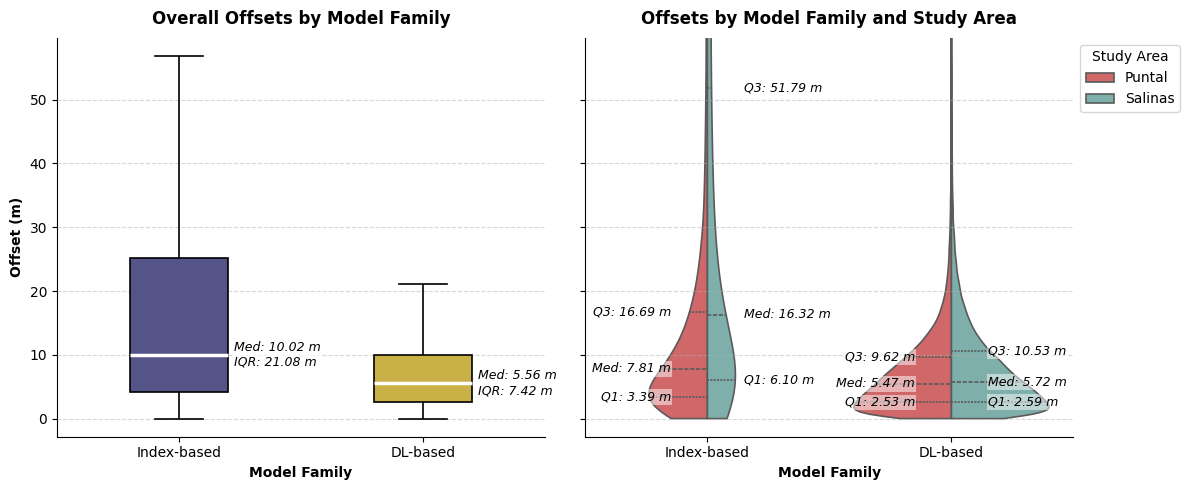

In [8]:
# Create a figure showing the overall boxplots for the two families of models (index-based and DL-based) across both study areas
overall_df_index = pd.concat([off_puntal_index, off_salinas_index], ignore_index=True)
overall_df_dl = pd.concat([off_puntal_dl, off_salinas_dl], ignore_index=True)
overall_df = pd.concat([overall_df_index, overall_df_dl], ignore_index=True)

# Remove data in 'Study Area' = 'Puntal' where 'transect_id' is less than 15
#overall_df = overall_df[~((overall_df['Study Area'] == 'Puntal') & (overall_df['transect_id'] < 15))]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# ==========================================
# PANEL IZQUIERDO: Boxplot
# ==========================================
sns.boxplot(
    x="Model Type",
    y="offset",
    data=overall_df,
    showfliers=False,
    width=0.4,
    palette=[palette[0], palette[1]], # Aplicamos tus colores
    linewidth=1.2,
    # Hacemos que la caja tenga borde negro y la mediana sea blanca y más gruesa para destacar
    boxprops=dict(edgecolor="black"), 
    medianprops=dict(color="white", linewidth=2.5),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    ax=axes[0]
)

axes[0].set_title("Overall Offsets by Model Family", fontsize=12, pad=10, fontweight='bold')
axes[0].set_xlabel("Model Family", fontweight='bold')
axes[0].set_ylabel("Offset (m)", fontweight='bold')

# Calcular y añadir el texto de Mediana e IQR
# Obtenemos los tipos de modelo en el orden en que aparecen en el gráfico
model_types = overall_df['Model Type'].unique() 

for i, model in enumerate(model_types):
    # Filtramos los datos de ese modelo
    data_subset = overall_df[overall_df['Model Type'] == model]['offset']
    
    # Calculamos métricas
    median_val = data_subset.median()
    q1 = data_subset.quantile(0.25)
    q3 = data_subset.quantile(0.75)
    iqr_val = q3 - q1
    
    # Añadimos el texto en la gráfica
    # Colocamos el texto a la derecha del boxplot sumando un pequeño offset en el eje X (i + 0.25)
    axes[0].text(
        i + 0.225,
        median_val,
        f"Med: {median_val:.2f} m\nIQR: {iqr_val:.2f} m",
        color="black",
        fontstyle="italic",
        fontsize=9,
        verticalalignment="center",
        bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1)
    )

# Obtenemos el límite para aplicarlo al segundo panel (tal como tenías)
ylim = axes[0].get_ylim()

# ==========================================
# PANEL DERECHO: Violinplot
# ==========================================
# IMPORTANTE: Usamos overall_df (sin filtrar) para que el KDE sea correcto
sns.violinplot(
    x="Model Type",
    y="offset",
    hue="Study Area",
    data=overall_df, 
    split=True,            
    inner="quartile",
    cut=0,  # Evita recortar los violines
    gridsize=1000,  # Aumenta la resolución del KDE para suavizar los violines
    palette=[palette[2], palette[3]], 
    linewidth=1.2,
    ax=axes[1]
)

# Aplicamos el zoom aquí para que coincida con el boxplot
axes[1].set_ylim(ylim)

axes[1].set_title("Offsets by Model Family and Study Area", fontsize=12, pad=10, fontweight='bold')
axes[1].set_xlabel("Model Family", fontweight='bold')
axes[1].set_ylabel("") 

# --- AÑADIR ETIQUETAS DE PERCENTILES ---
study_areas = overall_df['Study Area'].unique() # ["Puntal", "Salinas"]

for i, model in enumerate(model_types):
    for j, area in enumerate(study_areas):
        # Filtramos por modelo y área
        subset = overall_df[(overall_df['Model Type'] == model) & (overall_df['Study Area'] == area)]['offset']
        
        # Calculamos percentiles
        q1, med, q3 = subset.quantile([0.25, 0.5, 0.75])
        
        # Posicionamiento X: 
        # Si j=0 (Puntal - lado izquierdo), desplazamos a la izquierda (-0.22)
        # Si j=1 (Salinas - lado derecho), desplazamos a la derecha (+0.22)
        #if model == "Index-based":
        x_pos = i - 0.15 if j == 0 else i + 0.15
        align = 'right' if j == 0 else 'left'
        
        # Iteramos sobre las tres métricas para colocarlas en sus posiciones Y correspondientes
        metrics = [("Q3", q3), ("Med", med), ("Q1", q1)]
        
        for label_name, val in metrics:
            # Solo dibujamos si el valor está dentro del rango visible definido por ylim
            if ylim[0] <= val <= ylim[1]:
                axes[1].text(
                    x_pos, val, f"{label_name}: {val:.2f} m",
                    fontsize=9, color="black",
                    fontstyle="italic",
                    verticalalignment="center", horizontalalignment=align,
                    bbox=dict(facecolor="white", alpha=0.5, edgecolor="none", pad=1)
                )

# Ajustar la leyenda
axes[1].legend(title="Study Area", loc='upper left', bbox_to_anchor=(1, 1))

sns.despine()
plt.tight_layout()
plt.show()
fig.savefig(
    "../results/figures/offsets_assessment/figure_overall_family_boxplots.png",
    dpi=300, bbox_inches='tight')

### Q2 - Within each family, which models are better and how are they biased?
#### Performance per family and prediction bias orientation (Hexbins)

This section aims to evaluate models intrinsically within their own family (Index-based or Deep Learning-based):
- **MAE Heatmaps**: First, we look at the raw error (MAE) of each specific architecture/encoder and water index/threshold technique combination to assess which setups yield the highest predictive power natively.
- **Hexbin Error Distributions**: Beyond absolute error magnitudes, the hexbin plots map the exact orientation of this error across distances. They reveal if models have a systematic *Seaward* or *Landward* **bias** depending on the specific shore location.

In [9]:
# Merge the metrics DataFrames by model family

# Add 'Index' and 'Threshold' columns by splitting 'model_name'
overall_index_metrics[['Index', 'Threshold']] = overall_index_metrics['model_name'].str.rsplit(' (', n=1, expand=True)
# Remove the parentheses from the 'Threshold' column
overall_index_metrics['Threshold'] = overall_index_metrics['Threshold'].str.replace(r'[\(\)]', '', regex=True)

# Add 'Arch' and 'Encoder' columns by splitting 'model_name'
overall_dl_metrics[['Arch', 'Encoder']] = overall_dl_metrics['model_name'].str.split(' \(', n=1, expand=True)
# Remove the closing parenthesis from the 'Encoder' column
overall_dl_metrics['Encoder'] = overall_dl_metrics['Encoder'].str.replace(r'[\)]', '', regex=True)

<>:9: SyntaxWarning: invalid escape sequence '\('
<>:9: SyntaxWarning: invalid escape sequence '\('
/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/358628960.py:9: SyntaxWarning: invalid escape sequence '\('
  overall_dl_metrics[['Arch', 'Encoder']] = overall_dl_metrics['model_name'].str.split(' \(', n=1, expand=True)


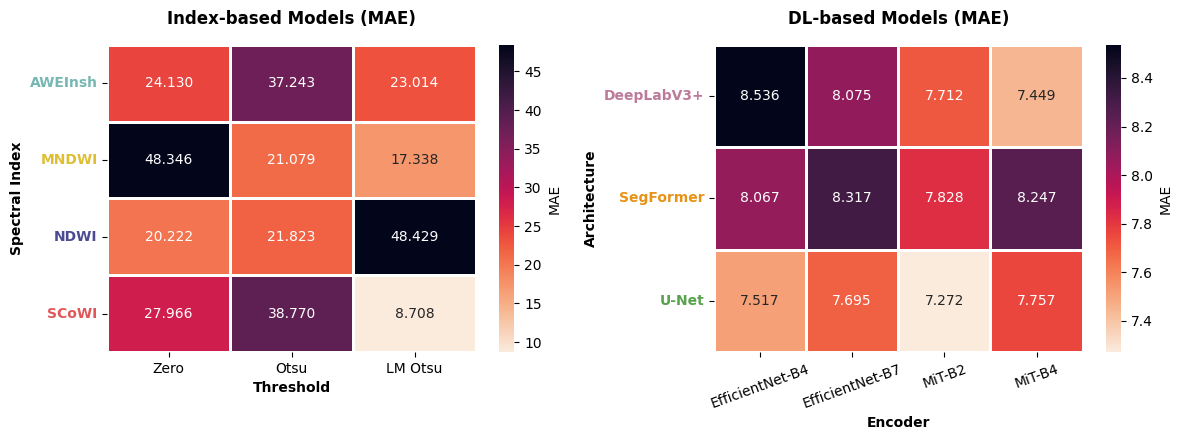

In [10]:
# Define the metric to plot
metric_to_plot = "MAE"  # Change this to "MAD", "Bias", "RMSE", or "R²" as needed

share_colorbar = False  # Set to False if you want separate colorbars for each heatmap

pivot_index = (
    overall_index_metrics.groupby(["Index", "Threshold"])[metric_to_plot]
    .mean()
    .reset_index()
    .pivot(index="Index", columns="Threshold", values=metric_to_plot)
)
# Reorder columns to Zero, Otsu, LM Otsu
pivot_index = pivot_index[["Zero", "Otsu", "LM Otsu"]]

pivot_dl = (
    overall_dl_metrics.groupby(["Arch", "Encoder"])[metric_to_plot]
    .mean()
    .reset_index()
    .pivot(index="Arch", columns="Encoder", values=metric_to_plot)
)

# ==========================================
# 3. LÓGICA DE COLORES SEGÚN LA MÉTRICA
# ==========================================
# Ajustamos los colores estéticamente para que encajen con la vibra de tu TFM
if metric_to_plot == "Bias":
    cmap_elegido = "vlag"  # Divergente (rojo/azul apagado)
    centro = 0             # El blanco/neutro estará exactamente en el 0
    if share_colorbar:
        min_val = min(pivot_index.min().min(), pivot_dl.min().min())
        max_val = max(pivot_index.max().max(), pivot_dl.max().max())
elif metric_to_plot == "R2":
    cmap_elegido = "mako"  # Secuencial oscuro a claro (verde azulado, pega con tu paleta)
    centro = None
    if share_colorbar:
        min_val = min(pivot_index.min().min(), pivot_dl.min().min())
        max_val = 1  # El máximo es 1
else:
    # Para errores (MAE, RMSE, MAD), los valores bajos son mejores. 
    # Usamos "rocket_r" (invertido) para que los errores altos destaquen en oscuro.
    cmap_elegido = "rocket_r" 
    centro = None
    if share_colorbar:
        min_val = min(pivot_index.min().min(), pivot_dl.min().min())
        max_val = max(pivot_index.max().max(), pivot_dl.max().max())

# ==========================================
# 4. CREACIÓN DE LOS HEATMAPS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel izquierdo: Modelos basados en Índices
sns.heatmap(
    pivot_index, 
    annot=True,          # Muestra el valor dentro de la celda
    fmt=".3f",           # 3 decimales
    cmap=cmap_elegido, 
    center=centro,
    vmin=min_val if share_colorbar else None,  # Si compartimos colorbar, usamos los mismos límites
    vmax=max_val if share_colorbar else None,
    linewidths=1,        # Separación entre celdas
    linecolor='white',
    cbar_kws={'label': metric_to_plot},
    ax=axes[0]
)
# Set custom colors for each y-tick label based on the model type
for tick_label in axes[0].get_yticklabels():
    index_name = tick_label.get_text().split()[0]  # Get the index name (e.g., "NDWI")
    color = model_colors.get(index_name, "black")  # Default to black if not found
    tick_label.set_color(color)
    tick_label.set_fontweight('bold')  # Make y-tick labels bold
axes[0].set_title(f"Index-based Models ({metric_to_plot})", fontsize=12, pad=15, fontweight='bold')
axes[0].set_xlabel("Threshold", fontweight='bold')
axes[0].set_ylabel("Spectral Index", fontweight='bold')
# Rotar etiquetas para que se lean bien
axes[0].tick_params(axis='y', rotation=0) 
# Quitar grid
axes[0].grid(False)

# Panel derecho: Modelos Deep Learning
sns.heatmap(
    pivot_dl, 
    annot=True, 
    fmt=".3f", 
    cmap=cmap_elegido, 
    center=centro,
    vmin=min_val if share_colorbar else None,
    vmax=max_val if share_colorbar else None,
    linewidths=1, 
    linecolor='white',
    cbar_kws={'label': metric_to_plot},
    ax=axes[1]
)
# Set custom colors for each y-tick label based on the model type
for tick_label in axes[1].get_yticklabels():
    arch_name = tick_label.get_text().split()[0]  # Get the architecture name (e.g., "U-Net")
    color = model_colors.get(arch_name, "black")  # Default to black if not found
    tick_label.set_color(color)
    tick_label.set_fontweight('bold')  # Make y-tick labels bold
axes[1].set_title(f"DL-based Models ({metric_to_plot})", fontsize=12, pad=15, fontweight='bold')
axes[1].set_xlabel("Encoder", fontweight='bold')
axes[1].set_ylabel("Architecture", fontweight='bold')
axes[1].tick_params(axis='y', rotation=0)
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(False)

plt.tight_layout()
plt.show()

fig.savefig(
    f"../results/figures/offsets_assessment/figure_heatmap_{metric_to_plot.lower()}.png",
    dpi=300, bbox_inches='tight')

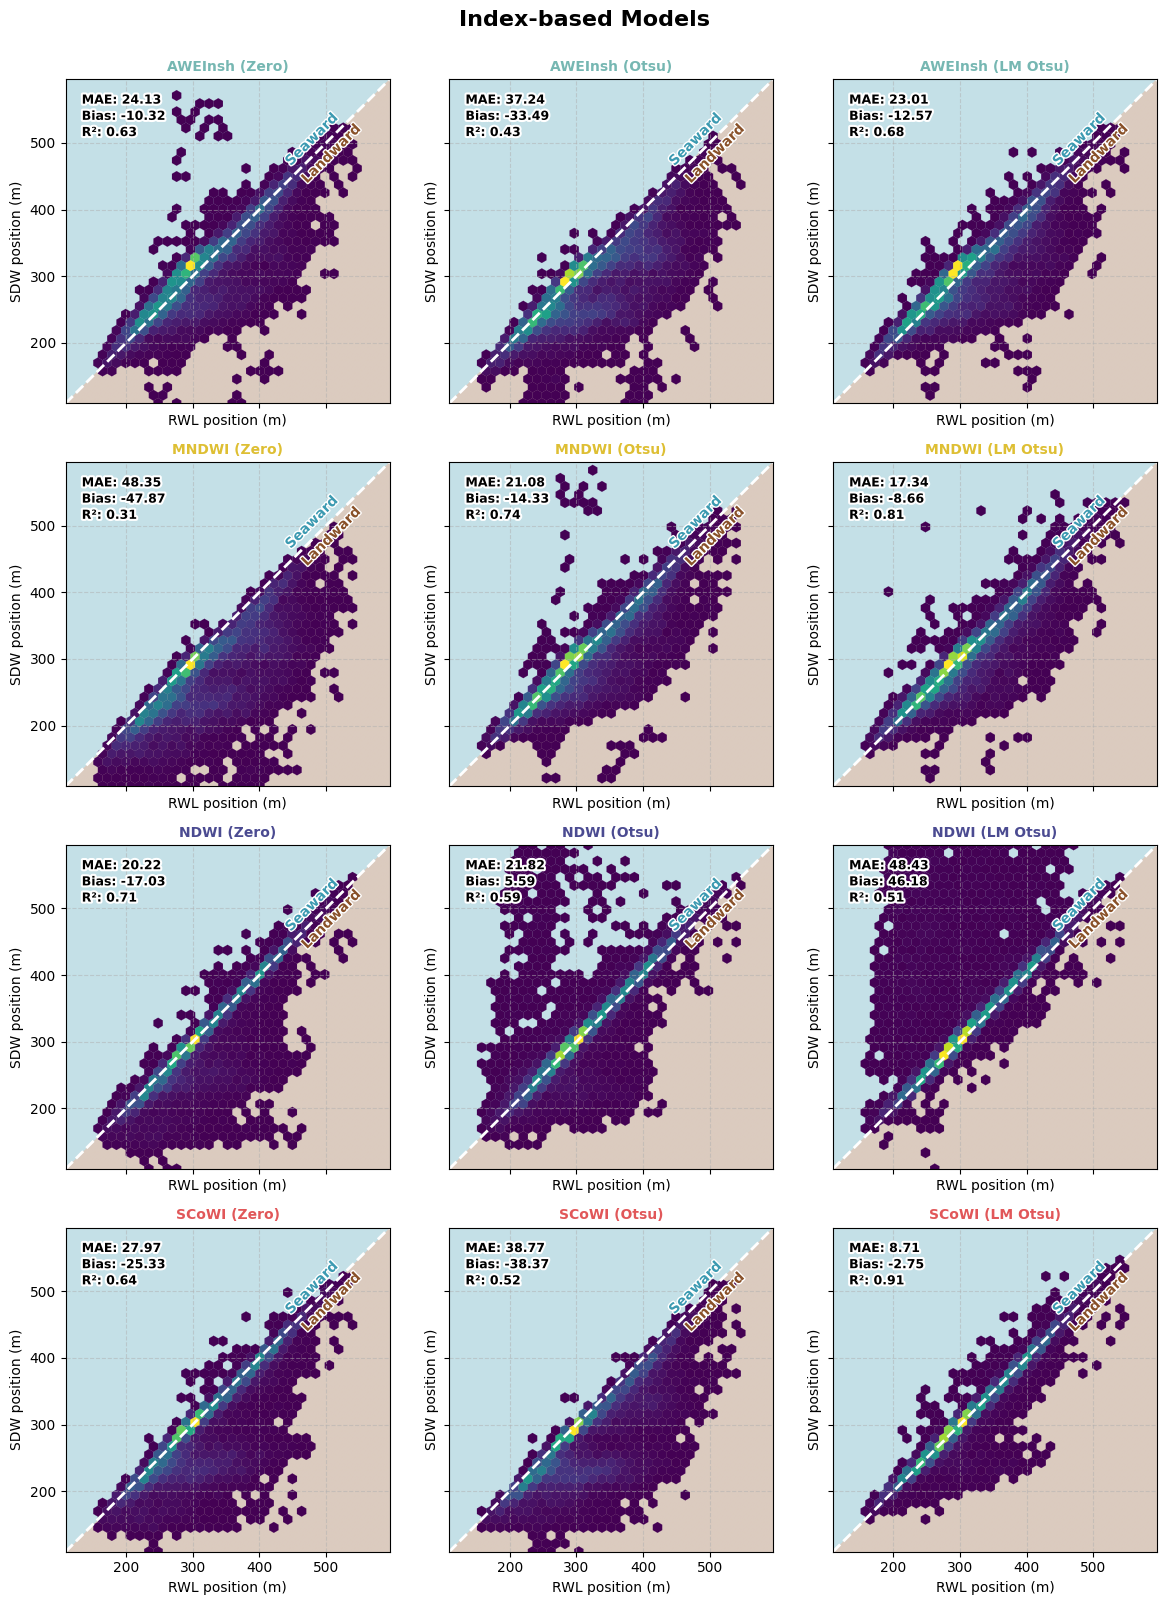

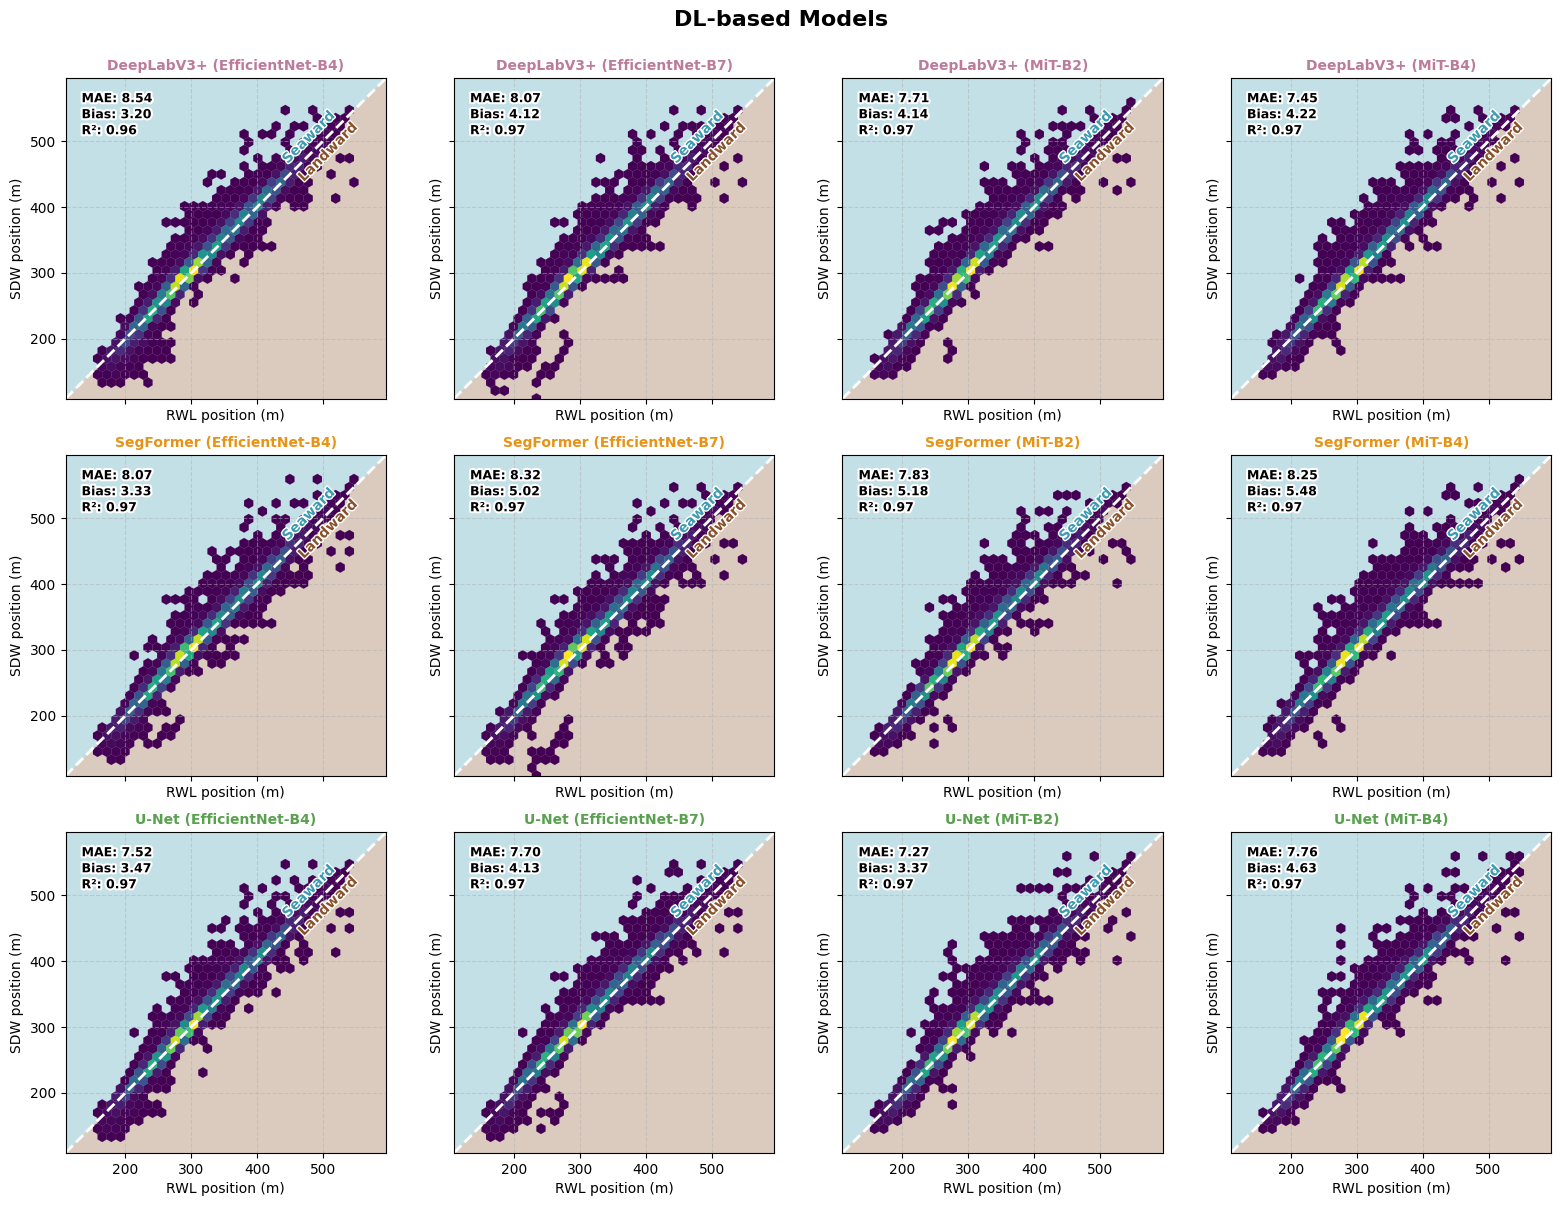

In [11]:
from matplotlib.colors import ListedColormap
import matplotlib.patheffects as pe

# Set custom palette for expressing landward vs seaward biases
direction_colors = {"Landward": "#895129", "Seaward": "#3C9AB1"}

def create_hexbin_plot(df, df_metrics, nrows, ncols, axis_range):

    # Set custom properties for the hexbin plot
    gridsize = 35  # Aumenta la resolución del hexbin
    xx, yy = np.meshgrid(
        np.linspace(axis_range[0], axis_range[1], 500),
        np.linspace(axis_range[0], axis_range[1], 500)
        )
    background = np.where(yy > xx, 1, 0)  # 1: sobre la bisectriz, 0: debajo
    cmap = ListedColormap(list(direction_colors.values())) # Landward/Seaward colors

    fig_width = 16  if nrows == 3 else 12  # Ancho total del gráfico
    fig_height = fig_width * (nrows / ncols)  # Mantener proporción

    fig, ax = plt.subplots(nrows, ncols, figsize=(fig_width, fig_height), sharey=True, sharex=True)
    ax = ax.flatten()

    # Reorder model_names for index-based models to be 1) Zero, 2) Otsu, 3) LM Otsu for each index
    model_names_list = df['model_name'].unique().tolist()
    # If index-based, sort by index name then by threshold order: Zero, Otsu, LM Otsu
    if df['Model Type'].unique()[0] == "Index-based":
        order_map = {"Zero": 0, "Otsu": 1, "LM Otsu": 2}
        def sort_key(x):
            x = str(x)
            if '(' in x and x.endswith(')'):
                idx = x.rfind('(')
                index_name = x[:idx].strip()
                th = x[idx+1:-1].strip()
                return (index_name, order_map.get(th, 99))
            return (x, 99)
        model_names_list.sort(key=sort_key)
    else:
        model_names_list.sort()

    for i, model in enumerate(model_names_list):
        subset = df[df['model_name'] == model]
        ax[i].imshow(
            background,
            extent=(axis_range[0], axis_range[1], axis_range[0], axis_range[1]),
            origin='lower',
            cmap=cmap,
            alpha=0.3,
            aspect='auto',
            zorder=0
        )
        hb = ax[i].hexbin(
            subset['distance_from_base_wl'], 
            subset['distance_from_base'], 
            extent=(axis_range[0], axis_range[1], axis_range[0], axis_range[1]),
            lw=0.1,
            gridsize=gridsize, cmap="viridis", mincnt=1
        )
        # Add a 1:1 line
        ax[i].plot(
            [axis_range[0], axis_range[1]],
            [axis_range[0], axis_range[1]],
            color='white',
            linestyle='--',
            linewidth=2,
            zorder=2
        )
        # Add metric annotation
        metrics = ['MAE', 'Bias', 'R²']
        y_pos = axis_range[1] - (axis_range[1] - axis_range[0]) * 0.075  # Position at 7.5% from the top
        for j, metric in enumerate(metrics):
            value = df_metrics[df_metrics['model_name'] == model][metric].values[0]
            ax[i].text(
                axis_range[0] + (axis_range[1] - axis_range[0]) * 0.05,  # 5% from the left
                y_pos - j * (axis_range[1] - axis_range[0]) * 0.05,  # Stacked vertically
                f"{metric}: {value:.2f}",
                color='black',
                fontsize=9,
                fontweight='bold',
                #bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2),
                zorder=3,
                path_effects=[pe.withStroke(linewidth=3, foreground="white")]
            )
        # Add 'Landward' and 'Seaward' labels at the top right corner
        ax[i].text(
            0.92, 0.87,
            "Landward",
            ha='right', va='top',
            transform=ax[i].transAxes,
            fontsize=10,
            rotation=45,
            weight="bold",
            color=direction_colors["Landward"],
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
        ax[i].text(
            0.85, 0.725,
            "Seaward",
            ha='right', va='bottom',
            transform=ax[i].transAxes,
            fontsize=10,
            rotation=45,
            weight="bold",
            color=direction_colors["Seaward"],
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
        ax[i].set_aspect('equal', adjustable='box')
        ax[i].set_xlim(axis_range[0], axis_range[1])
        ax[i].set_ylim(axis_range[0], axis_range[1])
        ax[i].set_title(model, fontsize=10, fontweight='bold', color=model_colors.get(model.split()[0], "#000000"))
        ax[i].set_xlabel("RWL position (m)")
        ax[i].set_ylabel("SDW position (m)")
        ax[i].set_aspect('equal', adjustable='box')
    fig.suptitle(f"{"Index-based" if df['Model Type'].unique()[0] == "Index-based" else "DL-based"} Models",
                 fontsize=16, fontweight='bold', y=1)
    plt.tight_layout()
    plt.show()
    return fig

# Create hexbin plots for index-based and DL-based models
axis_range_index = (overall_df_index['distance_from_base_wl'].min() - 50, overall_df_index['distance_from_base_wl'].max() + 50)
fig_index = create_hexbin_plot(overall_df_index, overall_index_metrics, nrows=4, ncols=3, axis_range=axis_range_index)
fig_index.savefig(
    "../results/figures/offsets_assessment/figure_hexbin_index_models.png",
    dpi=300, bbox_inches='tight')
axis_range_dl = (overall_df_dl['distance_from_base_wl'].min() - 50, overall_df_dl['distance_from_base_wl'].max() + 50)
fig_dl = create_hexbin_plot(overall_df_dl, overall_dl_metrics, nrows=3, ncols=4, axis_range=axis_range_dl)
fig_dl.savefig(
    "../results/figures/offsets_assessment/figure_hexbin_dl_models.png",
    dpi=300, bbox_inches='tight')

### Q3 - What factors account for the error variability?
#### Breakdown of sources of variability

Here, we explore the effect of different physical and morphological characteristics on the detected offsets.
- **Transect Variability**: Analysing the offsets by transect ID allows us to assess differences caused by coastal orientation and local conditions. 
- **Tide and Wave Height (Hs) Quartiles**: We categorize tidal levels and significant wave heights into quartiles to determine if extreme hydrodynamic conditions significantly increase the extraction error, leading for instance to wave run-up bias.

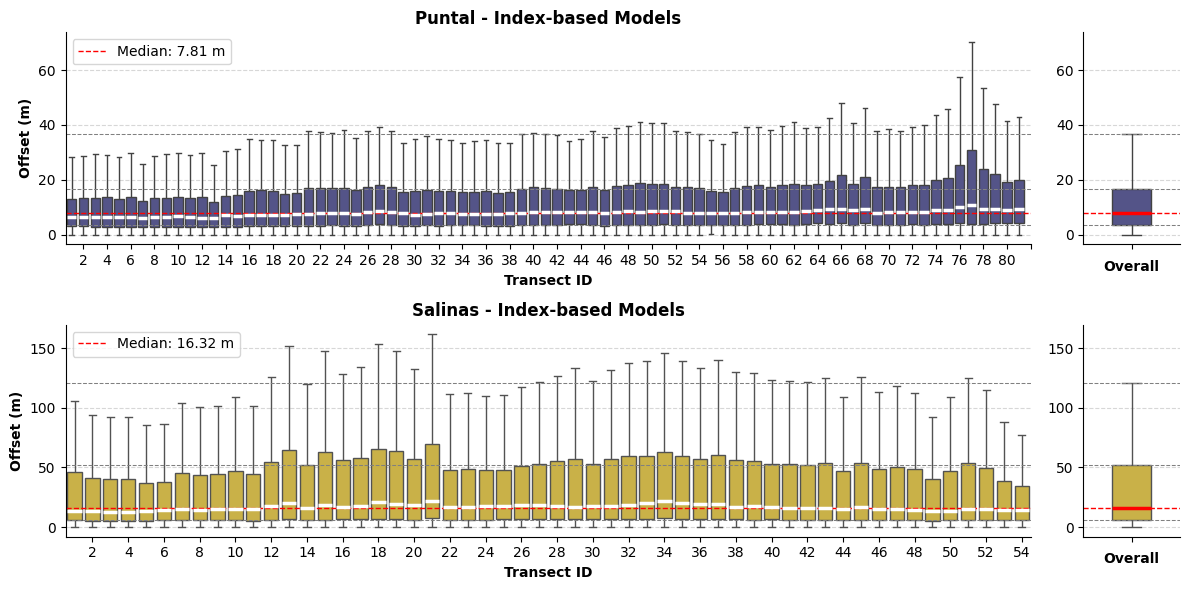

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6), width_ratios=[10, 1])

## PUNTAL
sns.boxplot(
    data=overall_df_index[overall_df_index['Study Area'] == 'Puntal'],
    x='transect_id',
    y='offset',
    showfliers=False,
    color=palette[0],
    medianprops=dict(color="white", linewidth=2.5),
    ax=ax[0, 0]
)
# Show horizontal lines at median, Q1, Q3, and max (defined as Q3 + 1.5*IQR) for Puntal
median_puntal = overall_df_index[overall_df_index['Study Area'] == 'Puntal']['offset'].median()
q1_puntal = overall_df_index[overall_df_index['Study Area'] == 'Puntal']['offset'].quantile(0.25)
q3_puntal = overall_df_index[overall_df_index['Study Area'] == 'Puntal']['offset'].quantile(0.75)
max_puntal = 1.5 * (q3_puntal - q1_puntal) + q3_puntal  # Define el máximo como Q3 + 1.5*IQR
for hline in [median_puntal, q1_puntal, q3_puntal, max_puntal]:
    if ax[0, 0].get_ylim()[0] <= hline <= ax[0, 0].get_ylim()[1]:  # Solo dibuja si está dentro del rango visible
        ax[0, 0].axhline(hline, color='red' if hline == median_puntal else 'gray', linestyle='--', 
                         lw=1 if hline == median_puntal else 0.75,
                         label=f'Median: {median_puntal:.2f} m' if hline == median_puntal else None)
ax[0, 0].legend(loc='upper left')
# Show only transect_id for every 2 transects to avoid overcrowding
ax[0, 0].set_xticks(overall_df_index[overall_df_index['Study Area'] == 'Puntal']['transect_id'].unique()[::2])
ax[0, 0].set_title("Puntal - Index-based Models", fontsize=12, fontweight='bold')
ax[0, 0].set_xlabel("Transect ID", fontweight='bold')
ax[0, 0].set_ylabel("Offset (m)", fontweight='bold')
# Get the y-axis limits from the first boxplot to apply the same limits to the second one
ylim = ax[0, 0].get_ylim()

# Show the overall Puntal boxplot in the right panel
sns.boxplot(
    data=overall_df_index[overall_df_index['Study Area'] == 'Puntal'],
    y='offset',
    color=palette[0],
    showfliers=False,
    width=0.4,
    medianprops=dict(color="red", linewidth=2.5),
    ax=ax[0, 1]
)
for hline in [median_puntal, q1_puntal, q3_puntal, max_puntal]:
    if ax[0, 1].get_ylim()[0] <= hline <= ax[0, 1].get_ylim()[1]:  # Solo dibuja si está dentro del rango visible
        ax[0, 1].axhline(hline, color='red' if hline == median_puntal else 'gray', linestyle='--',
                         lw=1 if hline == median_puntal else 0.75, label=None)
ax[0, 1].set_xlabel("Overall", fontweight='bold')
ax[0, 1].set_ylabel("")
ax[0, 1].set_ylim(ylim)  # Apply the same y-axis limits to the overall boxplot

## SALINAS
sns.boxplot(
    data=overall_df_index[overall_df_index['Study Area'] == 'Salinas'],
    x='transect_id',
    y='offset',
    showfliers=False,
    color=palette[1],
    medianprops=dict(color="white", linewidth=2.5),
    ax=ax[1, 0]
)
# Show horizontal lines at median, Q1, Q3, and max (defined as Q3 + 1.5*IQR) for Salinas
median_salinas = overall_df_index[overall_df_index['Study Area'] == 'Salinas']['offset'].median()
q1_salinas = overall_df_index[overall_df_index['Study Area'] == 'Salinas']['offset'].quantile(0.25)
q3_salinas = overall_df_index[overall_df_index['Study Area'] == 'Salinas']['offset'].quantile(0.75)
max_salinas = 1.5 * (q3_salinas - q1_salinas) + q3_salinas  # Define el máximo como Q3 + 1.5*IQR
for hline in [median_salinas, q1_salinas, q3_salinas, max_salinas]:
    if ax[1, 0].get_ylim()[0] <= hline <= ax[1, 0].get_ylim()[1]:  # Solo dibuja si está dentro del rango visible
        ax[1, 0].axhline(hline, color='red' if hline == median_salinas else 'gray', linestyle='--', 
                         lw=1 if hline == median_salinas else 0.75,
                         label=f'Median: {median_salinas:.2f} m' if hline == median_salinas else None)
ax[1, 0].legend(loc='upper left')
# Show only transect_id for every 2 transects to avoid overcrowding
ax[1, 0].set_xticks(overall_df_index[overall_df_index['Study Area'] == 'Salinas']['transect_id'].unique()[::2])
ax[1, 0].set_title("Salinas - Index-based Models", fontsize=12, fontweight='bold')
ax[1, 0].set_xlabel("Transect ID", fontweight='bold')
ax[1, 0].set_ylabel("Offset (m)", fontweight='bold')
# Get the y-axis limits from the first boxplot to apply the same limits to the second one
ylim = ax[1, 0].get_ylim()
# Show the overall Salinas boxplot in the right panel
sns.boxplot(
    data=overall_df_index[overall_df_index['Study Area'] == 'Salinas'],
    y='offset',
    color=palette[1],
    showfliers=False,
    width=0.4,
    medianprops=dict(color="red", linewidth=2.5),
    ax=ax[1, 1]
)
for hline in [median_salinas, q1_salinas, q3_salinas, max_salinas]:
    if ax[1, 1].get_ylim()[0] <= hline <= ax[1, 1].get_ylim()[1]:  # Solo dibuja si está dentro del rango visible
        ax[1, 1].axhline(hline, color='red' if hline == median_salinas else 'gray', linestyle='--', 
                         lw=1 if hline == median_salinas else 0.75, label=None)
ax[1, 1].set_xlabel("Overall", fontweight='bold')
ax[1, 1].set_ylabel("")
ax[1, 1].set_ylim(ylim)  # Apply the same y-axis limits to the overall boxplot
sns.despine()
plt.tight_layout()
plt.show()
fig.savefig(
    "../results/figures/offsets_assessment/figure_boxplot_by_transect_index_models.png",
    dpi=300, bbox_inches='tight')

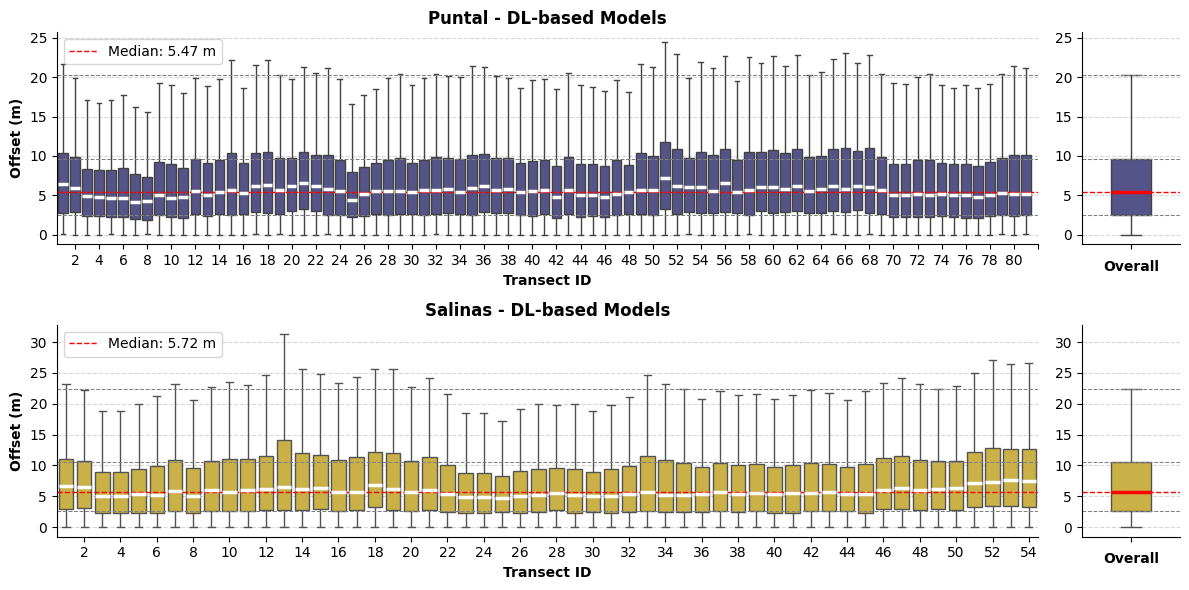

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6), width_ratios=[10, 1])

## PUNTAL
sns.boxplot(
    data=overall_df_dl[overall_df_dl['Study Area'] == 'Puntal'],
    x='transect_id',
    y='offset',
    showfliers=False,
    color=palette[0],
    medianprops=dict(color="white", linewidth=2.5),
    ax=ax[0, 0]
)
# Show horizontal lines at median, Q1, Q3, and max (defined as Q3 + 1.5*IQR) for Puntal
median_puntal = overall_df_dl[overall_df_dl['Study Area'] == 'Puntal']['offset'].median()
q1_puntal = overall_df_dl[overall_df_dl['Study Area'] == 'Puntal']['offset'].quantile(0.25)
q3_puntal = overall_df_dl[overall_df_dl['Study Area'] == 'Puntal']['offset'].quantile(0.75)
max_puntal = 1.5 * (q3_puntal - q1_puntal) + q3_puntal  # Define el máximo como Q3 + 1.5*IQR
for hline in [median_puntal, q1_puntal, q3_puntal, max_puntal]:
    if ax[0, 0].get_ylim()[0] <= hline <= ax[0, 0].get_ylim()[1]:  # Solo dibuja si está dentro del rango visible
        ax[0, 0].axhline(hline, color='red' if hline == median_puntal else 'gray', linestyle='--',
                         lw=1 if hline == median_puntal else 0.75,
                         label=f'Median: {median_puntal:.2f} m' if hline == median_puntal else None)
ax[0, 0].legend(loc='upper left')
# Show only transect_id for every 2 transects to avoid overcrowding
ax[0, 0].set_xticks(overall_df_dl[overall_df_dl['Study Area'] == 'Puntal']['transect_id'].unique()[::2])
ax[0, 0].set_title("Puntal - DL-based Models", fontsize=12, fontweight='bold')
ax[0, 0].set_xlabel("Transect ID", fontweight='bold')
ax[0, 0].set_ylabel("Offset (m)", fontweight='bold')
# Get the y-axis limits from the first boxplot to apply the same limits to the second one
ylim = ax[0, 0].get_ylim()

# Show the overall Puntal boxplot in the right panel
sns.boxplot(
    data=overall_df_dl[overall_df_dl['Study Area'] == 'Puntal'],
    y='offset',
    color=palette[0],
    showfliers=False,
    width=0.4,
    medianprops=dict(color="red", linewidth=2.5),
    ax=ax[0, 1]
)
for hline in [median_puntal, q1_puntal, q3_puntal, max_puntal]:
    if ax[0, 1].get_ylim()[0] <= hline <= ax[0, 1].get_ylim()[1]:  # Solo dibuja si está dentro del rango visible
        ax[0, 1].axhline(hline, color='red' if hline == median_puntal else 'gray', linestyle='--',
                         lw=1 if hline == median_puntal else 0.75, label=None)
ax[0, 1].set_xlabel("Overall", fontweight='bold')
ax[0, 1].set_ylabel("")
ax[0, 1].set_ylim(ylim)  # Apply the same y-axis limits to the overall boxplot

## SALINAS
sns.boxplot(
    data=overall_df_dl[overall_df_dl['Study Area'] == 'Salinas'],
    x='transect_id',
    y='offset',
    showfliers=False,
    color=palette[1],
    medianprops=dict(color="white", linewidth=2.5),
    ax=ax[1, 0]
)
# Show horizontal lines at median, Q1, Q3, and max (defined as Q3 + 1.5*IQR) for Salinas
median_salinas = overall_df_dl[overall_df_dl['Study Area'] == 'Salinas']['offset'].median()
q1_salinas = overall_df_dl[overall_df_dl['Study Area'] == 'Salinas']['offset'].quantile(0.25)
q3_salinas = overall_df_dl[overall_df_dl['Study Area'] == 'Salinas']['offset'].quantile(0.75)
max_salinas = 1.5 * (q3_salinas - q1_salinas) + q3_salinas  # Define el máximo como Q3 + 1.5*IQR
for hline in [median_salinas, q1_salinas, q3_salinas, max_salinas]:
    if ax[1, 0].get_ylim()[0] <= hline <= ax[1, 0].get_ylim()[1]:  # Solo dibuja si está dentro del rango visible
        ax[1, 0].axhline(hline, color='red' if hline == median_salinas else 'gray', linestyle='--',
                         lw=1 if hline == median_salinas else 0.75,
                         label=f'Median: {median_salinas:.2f} m' if hline == median_salinas else None)
ax[1, 0].legend(loc='upper left')
# Show only transect_id for every 2 transects to avoid overcrowding
ax[1, 0].set_xticks(overall_df_dl[overall_df_dl['Study Area'] == 'Salinas']['transect_id'].unique()[::2])
ax[1, 0].set_title("Salinas - DL-based Models", fontsize=12, fontweight='bold')
ax[1, 0].set_xlabel("Transect ID", fontweight='bold')
ax[1, 0].set_ylabel("Offset (m)", fontweight='bold')
# Get the y-axis limits from the first boxplot to apply the same limits to the second one
ylim = ax[1, 0].get_ylim()
# Show the overall Salinas boxplot in the right panel
sns.boxplot(
    data=overall_df_dl[overall_df_dl['Study Area'] == 'Salinas'],
    y='offset',
    color=palette[1],
    showfliers=False,
    width=0.4,
    medianprops=dict(color="red", linewidth=2.5),
    ax=ax[1, 1]
)
for hline in [median_salinas, q1_salinas, q3_salinas, max_salinas]:
    if ax[1, 1].get_ylim()[0] <= hline <= ax[1, 1].get_ylim()[1]:  # Solo dibuja si está dentro del rango visible
        ax[1, 1].axhline(hline, color='red' if hline == median_salinas else 'gray', linestyle='--', 
                         lw=1 if hline == median_salinas else 0.75, label=None)
ax[1, 1].set_xlabel("Overall", fontweight='bold')
ax[1, 1].set_ylabel("")
ax[1, 1].set_ylim(ylim)  # Apply the same y-axis limits to the overall boxplot
sns.despine()
plt.tight_layout()
plt.show()
fig.savefig(
    "../results/figures/offsets_assessment/figure_boxplot_by_transect_dl_models.png",
    dpi=300, bbox_inches='tight')

/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/522114248.py:25: UserWarning: The palette list has more values (7) than needed (2), which may not be intended.
  sns.stripplot(
/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/522114248.py:25: UserWarning: The palette list has more values (7) than needed (2), which may not be intended.
  sns.stripplot(
/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/522114248.py:25: UserWarning: The palette list has more values (7) than needed (2), which may not be intended.
  sns.stripplot(
/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/522114248.py:25: UserWarning: The palette list has more values (7) than needed (2), which may not be intended.
  sns.stripplot(


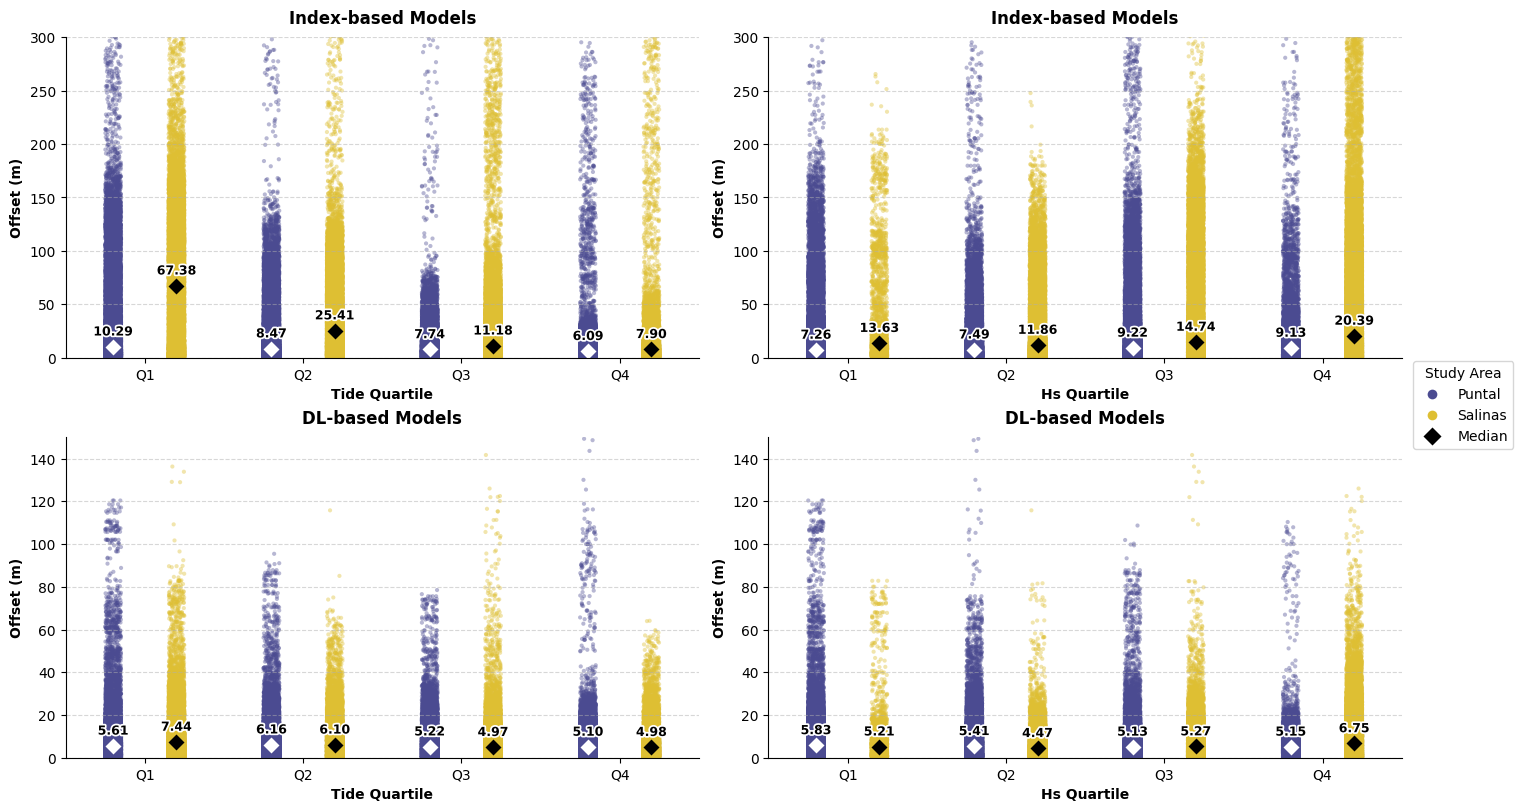

In [14]:
# Calculamos los cuartiles (igual que en tu código)
overall_df_index['tide_quartile'] = pd.qcut(overall_df_index['tide'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
overall_df_index['hs_quartile'] = pd.qcut(overall_df_index['hs'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
overall_df_dl['tide_quartile'] = pd.qcut(overall_df_dl['tide'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
overall_df_dl['hs_quartile'] = pd.qcut(overall_df_dl['hs'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

# Crear figura
fig, ax = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)

# Aseguramos el orden de las áreas para el cálculo matemático de posiciones
hue_order = overall_df_index['Study Area'].unique() 
quartiles = ['Q1', 'Q2', 'Q3', 'Q4']

# Definimos las configuraciones de cada panel para evitar repetir código
configs = [
    (overall_df_index, 'tide_quartile', "Index-based Models", "Tide Quartile", ax[0, 0]),
    (overall_df_index, 'hs_quartile', "Index-based Models", "Hs Quartile", ax[0, 1]),
    (overall_df_dl, 'tide_quartile', "DL-based Models", "Tide Quartile", ax[1, 0]),
    (overall_df_dl, 'hs_quartile', "DL-based Models", "Hs Quartile", ax[1, 1])
]

for df, x_col, title, xlabel, current_ax in configs:
    
    # 1. Nube de puntos (Stripplot)
    sns.stripplot(
        data=df, x=x_col, y='offset', hue='Study Area',
        palette=palette, dodge=True, jitter=True, size=3, 
        alpha=0.4,          # Transparencia para no saturar
        zorder=1,           # Lo mandamos al fondo
        ax=current_ax
    )
    
    # 2. Puntos de la Mediana (Pointplot) superpuestos
    sns.pointplot(
        data=df, 
        x=x_col, 
        y='offset', 
        hue='Study Area',
        estimator=np.median,
        errorbar=None,
        dodge=0.4,                  
        linestyle='none', 
        markers='D',
        palette=['white', 'black'],
        markersize=6,
        zorder=2,
        ax=current_ax
    )
    # 3. Añadir las etiquetas con Path Effects
    y_range = current_ax.get_ylim()[1] - current_ax.get_ylim()[0]
    y_offset = y_range * 0.01 # Pequeño margen dinámico para que el texto quede justo encima del rombo
    
    for i, cat in enumerate(quartiles):
        for j, area in enumerate(hue_order):
            # Calculamos la mediana para esta combinación específica
            med_val = df[(df[x_col] == cat) & (df['Study Area'] == area)]['offset'].median()
            
            # Si no hay datos (NaN), saltamos
            if pd.isna(med_val):
                continue
                
            # Calculamos la posición X (-0.2 para el grupo izquierdo, +0.2 para el derecho)
            x_pos = i - 0.2 if j == 0 else i + 0.2
            
            # Dibujamos el texto
            current_ax.text(
                x_pos, 
                med_val + y_offset, 
                f"{med_val:.2f}",
                fontsize=9,
                fontweight='bold',
                color='black',
                ha='center',       # Centrado horizontalmente sobre el punto
                va='bottom',       # Alineado desde abajo
                zorder=3,          # Aseguramos que esté por encima de todo
                path_effects=[pe.withStroke(linewidth=2.5, foreground='white')]
            )

    # 3. Formato de los ejes
    current_ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    current_ax.set_xlabel(xlabel, fontweight='bold')
    current_ax.set_ylabel("Offset (m)", fontweight='bold')
    
    # Ocultamos las leyendas individuales generadas por Seaborn
    if current_ax.get_legend() is not None:
        current_ax.legend_.remove()

# 4. Añadir una única leyenda global para toda la figura
# Extraemos los handles del primer panel (solo los dos primeros correspondientes al stripplot original)
handles, labels = ax[0, 0].get_legend_handles_labels()
# Keep only the first two handles (corresponding to the Study Area hues) for the legend
handles = handles[:2]
labels = labels[:2]

# Establecer la opacidad de los handles de la leyenda al 100%
for handle in handles:
    handle.set_alpha(1.0)
    handle.set_markersize(7)  # Aumentar el tamaño de los marcadores en la leyenda para mejor visibilidad

# Add a handle for the median points (rombos) to the legend
handles.append(plt.Line2D([0], [0], marker='D', color='w', markerfacecolor='black', markersize=10, linestyle='none'))
labels.append('Median')
fig.legend(handles, labels, title="Study Area", loc='center left', bbox_to_anchor=(1, 0.5))


# Set custom y-axis limts
ax[0, 0].set_ylim([0, 300])
ax[0, 1].set_ylim([0, 300])
ax[1, 0].set_ylim([0, 150])
ax[1, 1].set_ylim([0, 150])

sns.despine() # Elimina marcos superior y derecho para dar más ligereza
plt.show()
fig.savefig(
    "../results/figures/offsets_assessment/figure_stripplot_by_quartiles.png",
    dpi=300, bbox_inches='tight')

/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/966191660.py:39: UserWarning: The palette list has more values (7) than needed (2), which may not be intended.
  sns.pointplot(
/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/966191660.py:39: UserWarning: The palette list has more values (7) than needed (2), which may not be intended.
  sns.pointplot(
/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/966191660.py:39: UserWarning: The palette list has more values (7) than needed (2), which may not be intended.
  sns.pointplot(
/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_1653/966191660.py:39: UserWarning: The palette list has more values (7) than needed (2), which may not be intended.
  sns.pointplot(


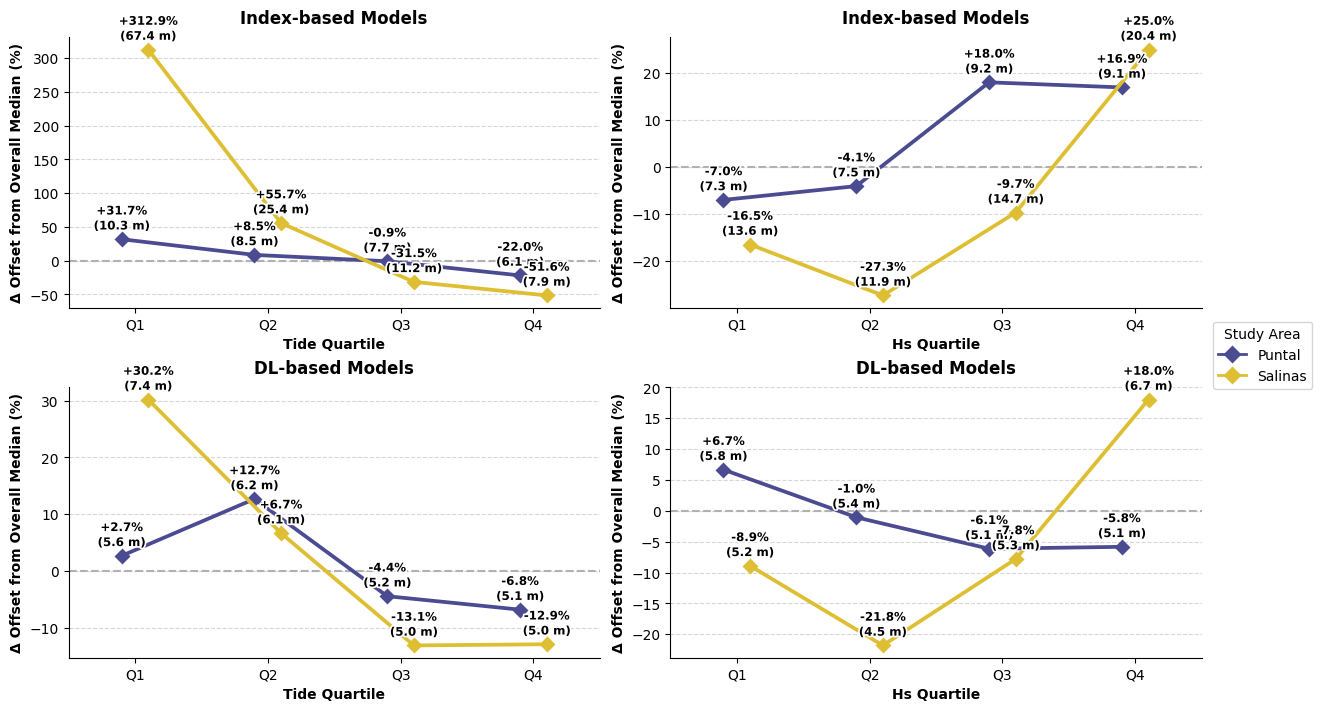

In [18]:
# Calculamos los cuartiles
overall_df_index['tide_quartile'] = pd.qcut(overall_df_index['tide'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
overall_df_index['hs_quartile'] = pd.qcut(overall_df_index['hs'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
overall_df_dl['tide_quartile'] = pd.qcut(overall_df_dl['tide'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
overall_df_dl['hs_quartile'] = pd.qcut(overall_df_dl['hs'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

# Crear figura
fig, ax = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)

# Aseguramos el orden de las áreas
hue_order = overall_df_index['Study Area'].unique() 
quartiles = ['Q1', 'Q2', 'Q3', 'Q4']

# Configuraciones de cada panel
configs = [
    (overall_df_index, 'tide_quartile', "Index-based Models", "Tide Quartile", ax[0, 0]),
    (overall_df_index, 'hs_quartile', "Index-based Models", "Hs Quartile", ax[0, 1]),
    (overall_df_dl, 'tide_quartile', "DL-based Models", "Tide Quartile", ax[1, 0]),
    (overall_df_dl, 'hs_quartile', "DL-based Models", "Hs Quartile", ax[1, 1])
]

# Ajuste visual del 'dodge'
dodge_val = 0.2 

for df, x_col, title, xlabel, current_ax in configs:
    
    # 1. PRE-CÁLCULO: Agrupamos las medianas por cuartil
    agg_df = df.groupby(['Study Area', x_col])['offset'].median().reset_index()
    agg_df['relative_offset'] = 0.0
    
    for area in hue_order:
        baseline = df[df['Study Area'] == area]['offset'].median()
        
        if baseline > 0:
            mask = agg_df['Study Area'] == area
            agg_df.loc[mask, 'relative_offset'] = ((agg_df.loc[mask, 'offset'] - baseline) / baseline) * 100
            
    # 2. Puntos y líneas de la Mediana relativa (Pointplot)
    sns.pointplot(
        data=agg_df, 
        x=x_col, 
        y='relative_offset', 
        hue='Study Area',
        hue_order=hue_order,
        dodge=dodge_val,                  
        linestyle='-',     
        markers='D',
        palette=palette,   
        markersize=6,
        zorder=3,
        ax=current_ax
    )
    
    # Añadimos una línea horizontal de referencia en el 0%
    current_ax.axhline(0, color='gray', linestyle='--', linewidth=1.5, zorder=1, alpha=0.6)
    
    # 3. Añadir las etiquetas con Path Effects
    y_range = current_ax.get_ylim()[1] - current_ax.get_ylim()[0]
    y_offset = y_range * 0.025 
    
    for i, cat in enumerate(quartiles):
        for j, area in enumerate(hue_order):
            # Extraemos tanto el valor relativo como el absoluto
            row_data = agg_df[(agg_df[x_col] == cat) & (agg_df['Study Area'] == area)]
            
            if row_data.empty or pd.isna(row_data['relative_offset'].values[0]):
                continue
                
            rel_val = row_data['relative_offset'].values[0]
            abs_val = row_data['offset'].values[0] # <--- ¡Aquí extraemos el valor absoluto!
            
            # Cálculo de la posición X
            x_pos = i - (dodge_val/2) if j == 0 else i + (dodge_val/2)
            
            # Formateamos el texto: +X.X% (Y.Ym)
            text_str = f"{rel_val:+.1f}%\n({abs_val:.1f} m)" if rel_val != 0 else f"0%\n({abs_val:.1f} m)"
            
            current_ax.text(
                x_pos, 
                rel_val + y_offset, 
                text_str,
                fontsize=8.5, # Letra un pelín más pequeña para que encaje bien
                fontweight='bold',
                color='black',
                ha='center',       
                va='bottom',       
                zorder=4,          
                path_effects=[pe.withStroke(linewidth=2.5, foreground='white')]
            )

    # 4. Formato de los ejes
    current_ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    current_ax.set_xlabel(xlabel, fontweight='bold')
    current_ax.set_ylabel("Δ Offset from Overall Median (%)", fontweight='bold')
    
    # Ocultamos las leyendas individuales
    if current_ax.get_legend() is not None:
        current_ax.legend_.remove()

# 5. Añadir una única leyenda global para toda la figura
handles, labels = ax[0, 0].get_legend_handles_labels()

for handle in handles:
    handle.set_alpha(1.0)
    handle.set_linewidth(2) 
    handle.set_markersize(7)

fig.legend(handles, labels, title="Study Area", loc='center left', bbox_to_anchor=(1, 0.5))

sns.despine() 
plt.show()

# Guardar figura
fig.savefig(
    "../results/figures/offsets_assessment/figure_pointplot_relative_quartiles.png",
    dpi=300, bbox_inches='tight')

### Q4 - How do the models generalize across the two beaches?
#### Cross-site consistency 

This analytical step investigates robustness. We visualize the Mean Absolute Error (MAE) difference ($\Delta$ MAE) between the Puntal and Salinas datasets for each model. A low $\Delta$ indicates that the model generalizes well across the two distinctly different study areas, whilst a large value suggests site-specific overfitting or dependency on local morphologies.

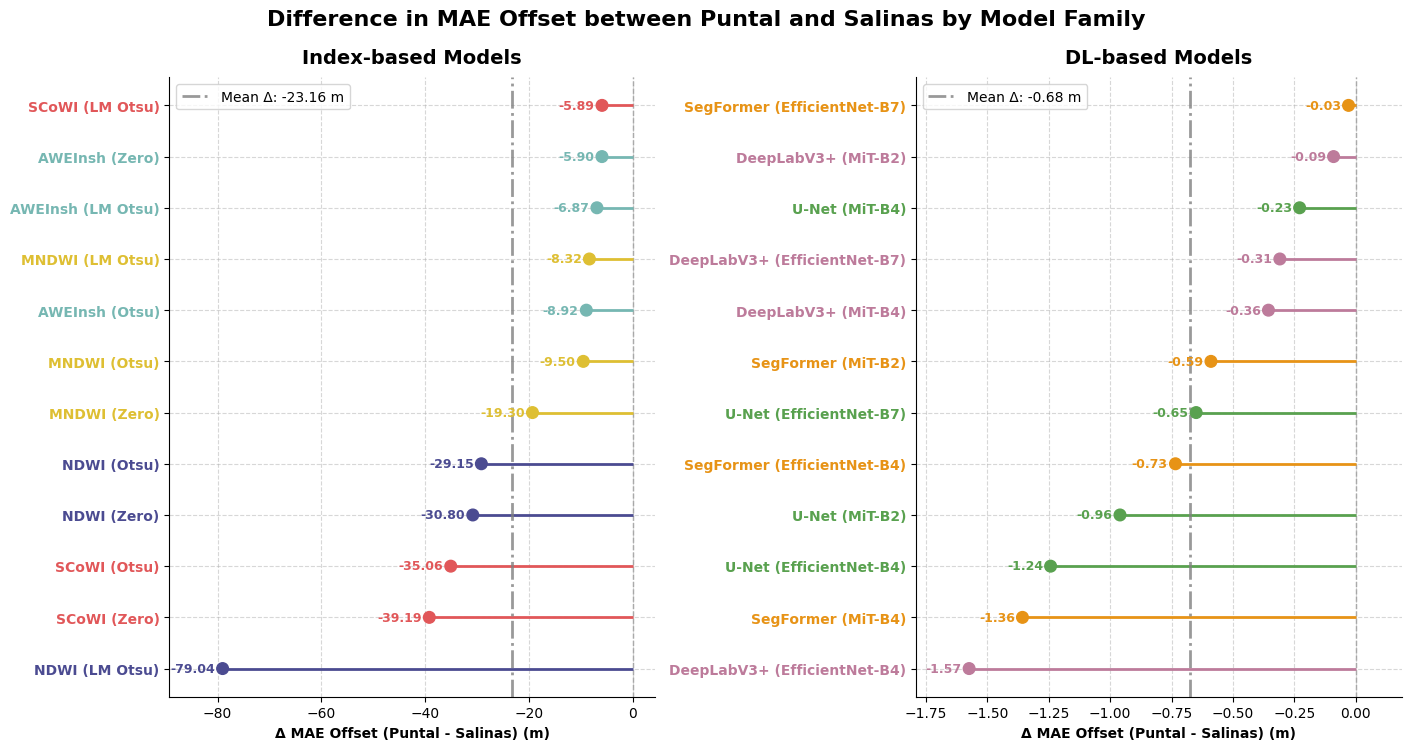

In [20]:
# Creamos la figura con 2 subplots (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Agrupamos los datasets y títulos para iterar sobre ellos
datasets = [
    (overall_df_index, "Index-based Models", axes[0]),
    (overall_df_dl, "DL-based Models", axes[1])
]

delta_maes = []  # Lista para almacenar los Δ MAE de cada modelo para el cálculo de la media general

for df, title, ax in datasets:
    # 1. Preparación de los datos
    # Calculamos la media de los offsets para cada Área de Estudio y modelo
    mean_offsets = (
        df.groupby(['model_name', 'Study Area'])['offset'].mean().reset_index()
        .pivot(index='model_name', columns='Study Area', values='offset')
    )
    
    # Calculamos el Δ (Puntal - Salinas)
    mean_offsets['Delta'] = mean_offsets['Puntal'] - mean_offsets['Salinas']
    
    # Ordenamos por el valor absoluto del Δ para poner las mayores diferencias primero
    mean_offsets = mean_offsets.reindex(mean_offsets['Delta'].abs().sort_values(ascending=True).index)
    
    # 2. Paleta de colores
    # Extraemos los colores para cada modelo ordenado usando tu diccionario model_colors
    colors = [model_colors.get(str(name).split()[0], "black") for name in mean_offsets.index]
    
    # 3. Dibujamos el Lollipop Chart
    # Líneas horizontales
    ax.hlines(y=mean_offsets.index, xmin=0, xmax=mean_offsets['Delta'], color=colors, linewidth=2)
    # Puntos en los extremos
    ax.scatter(mean_offsets["Delta"], mean_offsets.index, s=70, color=colors, zorder=3)
    
    # Añadimos una línea vertical en el 0 para referencia visual
    ax.axvline(0, color='gray', linestyle='--', linewidth=1, zorder=1, alpha=0.7)
    
    # Calculamos la media de la familia y añadimos una línea vertical
    mean_delta = mean_offsets['Delta'].mean()
    ax.axvline(mean_delta, color='gray', linestyle='-.', linewidth=2, zorder=2, alpha=0.8, label=f'Mean Δ: {mean_delta:.2f} m')
    ax.legend(loc='best')
    
    # 4. Añadimos las etiquetas de texto a izquierda o derecha
    # Calculamos un pequeño margen ('pad') dinámico basado en el rango de los datos (eje X)
    x_range = mean_offsets['Delta'].max() - mean_offsets['Delta'].min()
    pad = x_range * 0.02
    
    for y_pos, model_name in enumerate(mean_offsets.index):
        delta_val = mean_offsets.loc[model_name, 'Delta']
        color = model_colors.get(str(model_name).split()[0], "black")
        
        # Lógica de posición según el signo del valor
        if delta_val < 0:
            ha = 'right'
            text_x = delta_val - pad
        else:
            ha = 'left'
            text_x = delta_val + pad
            
        ax.text(
            text_x, y_pos, 
            f"{delta_val:.2f}", 
            va='center', ha=ha,
            fontsize=9, 
            color=color,
            fontweight='bold',
            zorder=4
        )
        delta_maes.append((model_name, delta_val))  # Guardamos el Δ MAE para este modelo

    # 5. Formato de los ejes y textos
    ax.set_xlim(mean_offsets['Delta'].min() - pad*7, mean_offsets['Delta'].max() + pad*7)  # Añadimos espacio extra a los lados
    ax.set_xlabel('Δ MAE Offset (Puntal - Salinas) (m)', fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
    
    # Invertimos el eje Y para que los modelos con mayor Δ queden arriba
    ax.invert_yaxis()
    
    # Coloreamos las etiquetas del eje Y
    for tick_label in ax.get_yticklabels():
        model_name = tick_label.get_text()
        tick_label.set_color(model_colors.get(str(model_name).split()[0], "black"))
        tick_label.set_fontweight('bold')

fig.suptitle('Difference in MAE Offset between Puntal and Salinas by Model Family', fontsize=16, fontweight='bold', y=1.05)
sns.despine()
plt.show()
fig.savefig(
    "../results/figures/offsets_assessment/figure_lollipop_delta.png",
    dpi=300, bbox_inches='tight')

### Q5 - Which are the best global models?
#### Final Multi-criteria Ranking

In this final section, we synthesize all the robust metrics computed earlier into heatmaps and bump charts to produce a final consensus on which architectures provide the best overall performance. The ranking comprehensively scales the metrics (where lower values denote better skill for error metrics, and higher values for $R^2$) to identify the top 3 global performers.

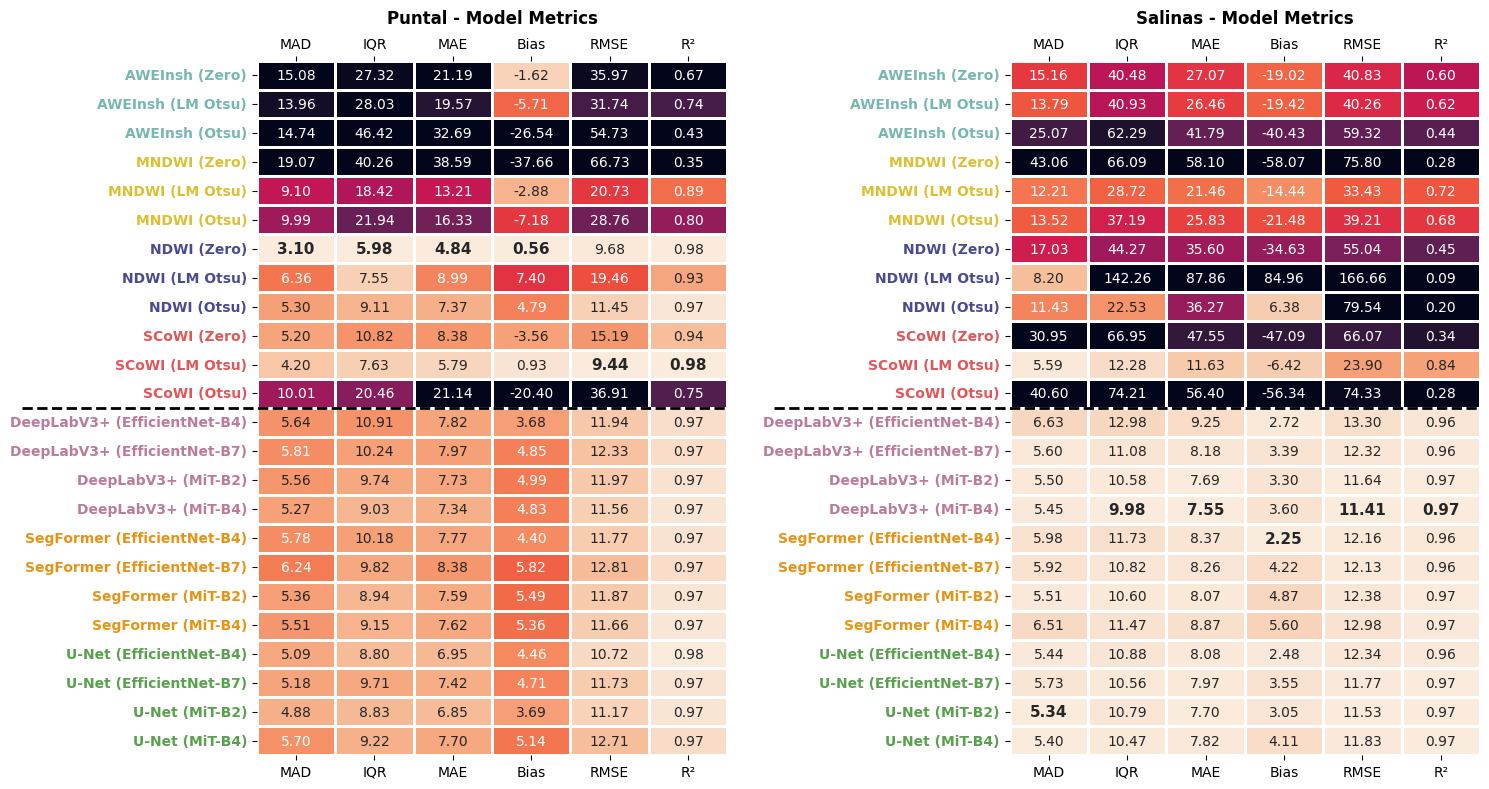

In [22]:
# 1. Definimos la función para normalizar colores por columna
def prepare_color_matrix(df):
    color_df = pd.DataFrame(index=df.index)
    for col in df.columns:
        s = df[col].copy()
        
        if col == "Bias":
            s = s.abs()
        elif col == "R²":
            s = -s
            
        p_max = s.quantile(0.90)
        p_min = s.min()
        
        if p_max - p_min == 0:
            scaled = s * 0
        else:
            scaled = (s - p_min) / (p_max - p_min)
        color_df[col] = scaled.clip(0, 1)
        
    return color_df

# 2. Preparamos los DataFrames originales
df_puntal_raw = puntal_metrics.set_index('model_name')[["MAD", "IQR", "MAE", "Bias", "RMSE", "R²"]]
df_salinas_raw = salinas_metrics.set_index('model_name')[["MAD", "IQR", "MAE", "Bias", "RMSE", "R²"]]

# 3. Preparamos las matrices de color
df_puntal_color = prepare_color_matrix(df_puntal_raw)
df_salinas_color = prepare_color_matrix(df_salinas_raw)

# 4. Creación de la figura
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
cmap_metricas = "rocket_r" 

# Agrupamos los datos para iterar sobre los paneles y no repetir código
paneles = [
    (axes[0], df_puntal_raw, df_puntal_color, "Puntal - Model Metrics"),
    (axes[1], df_salinas_raw, df_salinas_color, "Salinas - Model Metrics")
]

for ax, df_raw, df_color, title in paneles:
    # Dibujamos el heatmap
    sns.heatmap(
        data=df_color, 
        annot=df_raw, 
        fmt=".2f",
        cmap=cmap_metricas,
        linewidths=1,
        linecolor='white',
        cbar=False,
        ax=ax
    )
    
    # Formato básico
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("", fontweight='bold')
    ax.tick_params(axis='x', top=True, labeltop=True, bottom=True, labelbottom=True)
    ax.set_ylabel("", fontweight='bold')
    ax.tick_params(axis='y', rotation=0)
    ax.grid(False) # Aseguramos que el grid esté desactivado
    
    # --- Añadir línea separadora discontinua ---
    # Buscamos el índice (posición Y) de DeepLabV3+ para trazar la línea justo encima
    try:
        line_idx = list(df_raw.index).index("DeepLabV3+ (EfficientNet-B4)")
                
        # El ancho de la tabla va de 0 al número total de columnas
        num_cols = len(df_raw.columns)
        
        # Dibujamos una línea desde un valor X negativo (-3 o ajústalo si tus labels son muy largos) 
        # hasta el final de la tabla (num_cols), y desactivamos el recorte con clip_on=False
        ax.plot(
            [-3, num_cols], [line_idx, line_idx], 
            color='black', linestyle='--', linewidth=2, clip_on=False
        )
    except ValueError:
        pass # Si por algún motivo no encuentra el nombre, no dibuja la línea y no rompe el código
        
    # --- Poner en negrita el mejor valor de cada columna ---
    num_cols = len(df_raw.columns)
    for col_idx, col_name in enumerate(df_raw.columns):
        # Lógica para encontrar el índice (fila) del mejor valor según la métrica
        if col_name in ["MAD", "IQR", "MAE", "RMSE"]:
            best_row_idx = df_raw[col_name].argmin()  # El error más bajo
        elif col_name == "Bias":
            best_row_idx = df_raw[col_name].abs().argmin()  # El más cercano a 0
        elif col_name == "R²":
            best_row_idx = df_raw[col_name].argmax()  # El valor más alto
            
        # Seaborn guarda los textos de izquierda a derecha y de arriba a abajo.
        # Calculamos su posición plana (flat_index)
        flat_index = best_row_idx * num_cols + col_idx
        
        # Rescatamos el objeto de texto y le aplicamos la negrita
        texto = ax.texts[flat_index]
        texto.set_fontweight('bold')
        texto.set_fontsize(11)
        
    # Colorear las etiquetas del eje Y según el modelo
    for tick_label in ax.get_yticklabels():
        model_name = tick_label.get_text()
        arch_name = model_name.split()[0]
        color = model_colors.get(arch_name, "black")
        tick_label.set_color(color)
        tick_label.set_fontweight('bold')

plt.tight_layout()
# Give a little space between the two heatmaps
plt.subplots_adjust(wspace=0.6)
plt.show()

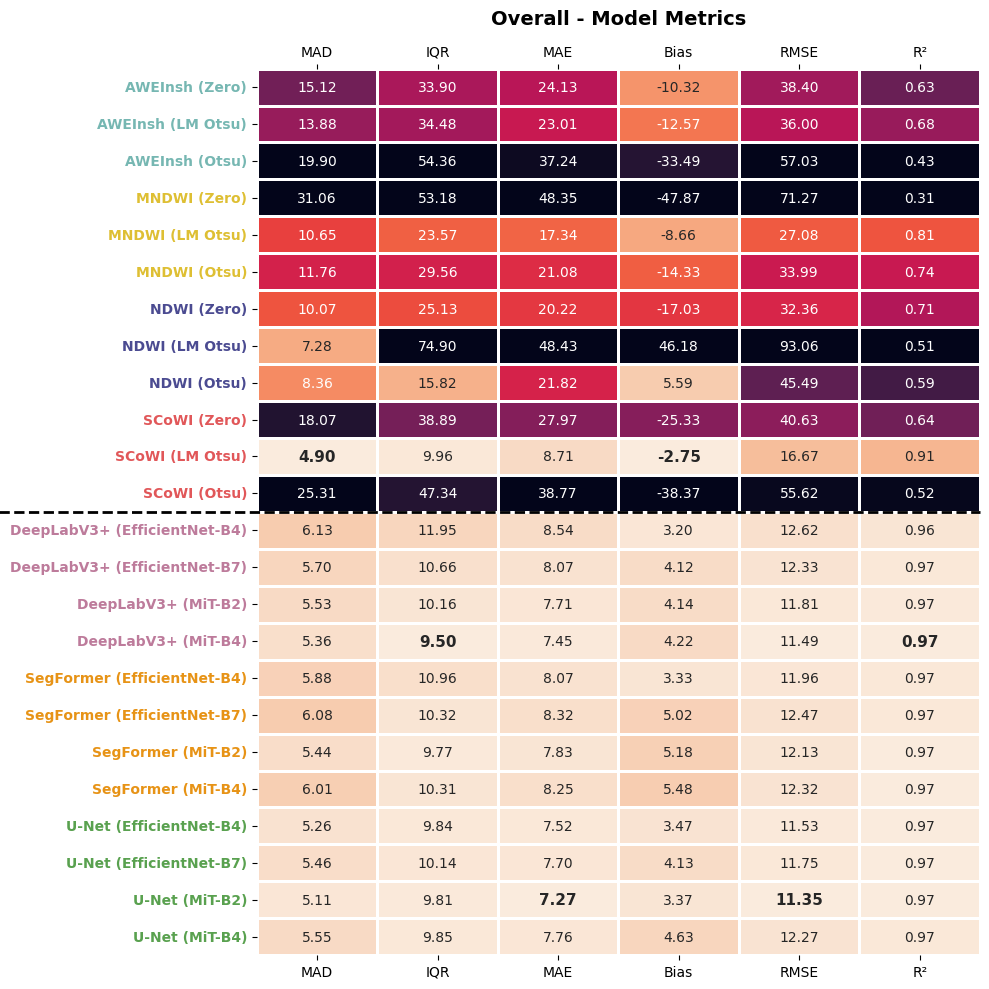

In [24]:
# 1. Prepare the raw DataFrames for overall metrics
df_combined_raw = pd.concat([
    overall_index_metrics.set_index('model_name')[["MAD", "IQR", "MAE", "Bias", "RMSE", "R²"]],
    overall_dl_metrics.set_index('model_name')[["MAD", "IQR", "MAE", "Bias", "RMSE", "R²"]]
])

# 2. Prepare the color matrices using the previously defined function
df_combined_color = prepare_color_matrix(df_combined_raw)

# 3. Create the figure
fig, ax = plt.subplots(figsize=(10, 10))
cmap_metricas = "rocket_r" 

# Draw the heatmap
sns.heatmap(
    data=df_combined_color, 
    annot=df_combined_raw, 
    fmt=".2f",
    cmap=cmap_metricas,
    linewidths=1,
    linecolor='white',
    cbar=False,
    ax=ax
)

# Basic formatting
ax.set_title("Overall - Model Metrics", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("", fontweight='bold')
ax.tick_params(axis='x', top=True, labeltop=True, bottom=True, labelbottom=True)
ax.set_ylabel("", fontweight='bold')
ax.tick_params(axis='y', rotation=0)
ax.grid(False) 

# --- Add dashed separator line ---
# Draw line between Index-based and DL-based models
line_idx = len(overall_index_metrics)
num_cols = len(df_combined_raw.columns)

ax.plot(
    [-3, num_cols], [line_idx, line_idx], 
    color='black', linestyle='--', linewidth=2, clip_on=False
)
    
# --- Bold the best value in each column ---
for col_idx, col_name in enumerate(df_combined_raw.columns):
    if col_name in ["MAD", "IQR", "MAE", "RMSE"]:
        best_row_idx = df_combined_raw[col_name].argmin()  # Lowest error
    elif col_name == "Bias":
        best_row_idx = df_combined_raw[col_name].abs().argmin()  # Closest to 0
    elif col_name == "R²":
        best_row_idx = df_combined_raw[col_name].argmax()  # Highest value
        
    flat_index = best_row_idx * num_cols + col_idx
    
    texto = ax.texts[flat_index]
    texto.set_fontweight('bold')
    texto.set_fontsize(11)
    
# Color the Y-axis labels according to the model family
for tick_label in ax.get_yticklabels():
    model_name = tick_label.get_text()
    arch_name = model_name.split()[0]
    color = model_colors.get(arch_name, "black")
    tick_label.set_color(color)
    tick_label.set_fontweight('bold')

plt.tight_layout()
plt.show()
fig.savefig(
    "../results/figures/offsets_assessment/figure_heatmap_overall_metrics.png",
    dpi=300, bbox_inches='tight')

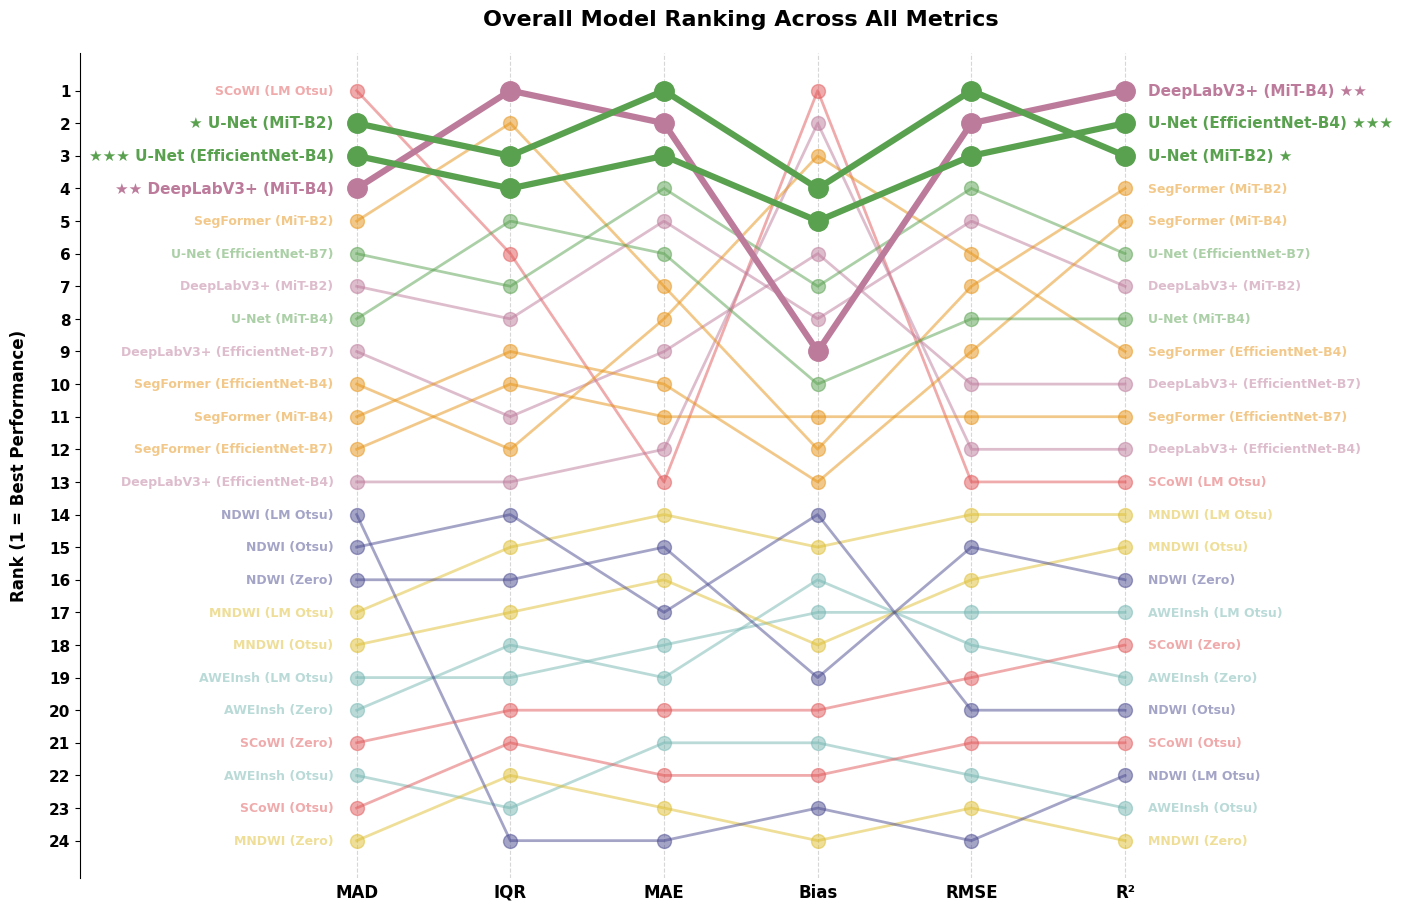

In [34]:
# 1. Calcular los rankings por métrica
ranks_df = pd.DataFrame(index=df_combined_raw.index)

for col in df_combined_raw.columns:
    if col == "Bias":
        ranks_df[col] = df_combined_raw[col].abs().rank(ascending=True, method='min')
    elif col == "R²":
        ranks_df[col] = df_combined_raw[col].rank(ascending=False, method='min')
    else:
        ranks_df[col] = df_combined_raw[col].rank(ascending=True, method='min')

# 2. Calcular el Ranking Global (Media de los rankings) y sacar el Top 3
mean_ranks = ranks_df.mean(axis=1)
# nsmallest(3) coge los 3 modelos con la media más baja (los mejores)
top3_models = mean_ranks.nsmallest(3).index.tolist()

# Asignamos los símbolos al Top 3
top3_symbols = {
    top3_models[0]: "★", # 1er puesto
    top3_models[1]: "★★",  # 2do puesto
    top3_models[2]: "★★★"    # 3er puesto
}

# 3. Configuración de la figura
fig, ax = plt.subplots(figsize=(14, 9), constrained_layout=True)

metrics = ranks_df.columns
x_positions = np.arange(len(metrics))

# 4. Dibujar las líneas (bump chart)
for model_name in ranks_df.index:
    arch_name = str(model_name).split()[0]
    color = model_colors.get(arch_name, "gray")
    y_values = ranks_df.loc[model_name]
    
    # Comprobamos si el modelo está en el Top 3 para darle más peso visual
    is_top3 = model_name in top3_models
    line_alpha = 1.0 if is_top3 else 0.5    # Resalta el Top 3, atenúa el resto
    line_width = 4.5 if is_top3 else 2.0    # Hace la línea más gruesa
    
    # Trazamos la línea y los puntos
    ax.plot(
        x_positions, y_values, 
        marker='o', markersize=10 if not is_top3 else 14, 
        linewidth=line_width, 
        color=color, alpha=line_alpha,
        zorder=5 if is_top3 else 3 # Aseguramos que el Top 3 se dibuje por encima
    )
    
    # Preparamos el texto de la izquierda con las estrellas si aplica
    symbol = top3_symbols.get(model_name, "")
    left_label = f"{symbol} {model_name}" if symbol else model_name
    right_label = f"{model_name} {symbol}" if symbol else model_name
    
    # Texto a la izquierda
    ax.text(
        x_positions[0] - 0.15, y_values.iloc[0], 
        left_label, 
        ha='right', va='center', 
        fontsize=11 if is_top3 else 9, 
        fontweight='black' if is_top3 else 'bold', 
        color=color, alpha=line_alpha, zorder=5
    )
    
    # Texto a la derecha
    ax.text(
        x_positions[-1] + 0.15, y_values.iloc[-1], 
        right_label, 
        ha='left', va='center', 
        fontsize=11 if is_top3 else 9, 
        fontweight='black' if is_top3 else 'bold', 
        color=color, alpha=line_alpha, zorder=5
    )

# 5. Formateo y estética de los ejes
ax.set_xticks(x_positions)
ax.set_xticklabels(metrics, fontweight='bold', fontsize=12)

# Invertimos el eje Y
ax.invert_yaxis()

# Forzamos los ticks del eje Y
max_rank = int(ranks_df.max().max())
ax.set_yticks(range(1, max_rank + 1))
ax.set_yticklabels([str(i) for i in range(1, max_rank + 1)], fontweight='bold', fontsize=11)

# Ajustamos límites de X
ax.set_xlim(-1.8, len(metrics) + 0.8)

# Guías verticales
# for x in x_positions:
#     ax.axvline(x, color='gray', linestyle=':', alpha=0.3, zorder=1)

ax.set_ylabel("Rank (1 = Best Performance)", fontweight='bold', fontsize=12, labelpad=15)
ax.set_title("Overall Model Ranking Across All Metrics", fontsize=16, fontweight='bold', pad=20)

# Keep only grid for y axis
ax.grid(False, axis='y')

sns.despine(bottom=True, top=True, right=True)
ax.tick_params(axis='x', length=0)

plt.show()
fig.savefig(
    "../results/figures/offsets_assessment/figure_bump_chart_ranking.png",
    dpi=300, bbox_inches='tight')